# Lending Club Data Science Project

## Abstract
This project conducts a comprehensive credit risk analysis using the Lending Club dataset. The primary objective is to identify key borrower attributes and financial indicators that strongly correlate with loan defaults. By leveraging advanced data preprocessing and machine learning techniques, we aim to build robust predictive models capable of estimating the probability of default for new loan applications.

## Problem & Motivation
Peer-to-peer (P2P) lending platforms, such as Lending Club, revolutionized personal finance by connecting individual investors directly with borrowers. However, this model shifts the credit risk entirely onto the investors. Accurately predicting loan defaults is critical because:
1. **Capital Preservation:** Investors stand to lose their principal if a borrower defaults.
2. **Platform Trust:** The long-term viability of P2P lending depends on delivering consistent returns to investors. High default rates can erode trust and liquidity.
3. **Optimized Lending:** Better risk models allow for more accurate interest rate assignments, ensuring fair pricing for borrowers and adequate compensation for investor risk.

This project is motivated by the need to develop a reliable, data-driven approach to risk assessment that minimizes financial exposure while maximizing investment returns.

## Data Collection
The dataset used in this project is sourced from Kaggle: <a href="https://www.kaggle.com/datasets/wordsforthewise/lending-club" style="color:blue;">Lending Club Dataset</a>. It contains comprehensive historical data on loans issued from 2007 to 2018, including various applicant attributes, loan characteristics, and the final loan status.

## 1. Environment Setup & Data Loading

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Load the accepted loans dataset
file_path = 'data/accepted_2007_to_2018Q4.csv'
print('Loading data with Polars...')
df = pl.read_csv(file_path, ignore_errors=True)
print(f'Initial shape: {df.shape}')
pd.set_option('display.max_rows', None)
display(df.head().to_pandas().T)


Loading data with Polars...


Initial shape: (2260701, 151)


,0,1,2,3,4
id,68407277,68355089,68341763,66310712,68476807
member_id,None,None,None,None,None
loan_amnt,3600.0,24700.0,20000.0,35000.0,10400.0
funded_amnt,3600.0,24700.0,20000.0,35000.0,10400.0
funded_amnt_inv,3600.0,24700.0,20000.0,35000.0,10400.0
term,36 months,36 months,60 months,60 months,60 months
int_rate,13.99,11.99,10.78,14.85,22.45
installment,123.03,820.28,432.66,829.9,289.91
grade,C,C,B,C,F
sub_grade,C4,C1,B4,C5,F1


### Discussion: To Use or Not to Use Lending Club's Grade?

Right after loading the dataset, we notice columns like `grade` and `sub_grade`. These are risk assessments calculated and assigned to borrowers by Lending Club themselves.
This raises a fundamental question: **Should we even use their grade as a feature in our model? Isn't it essentially "cheating" or copying someone else's homework?**

This is a classic dilemma in Data Science, and there are two valid approaches:

1. **The Purist Approach (Excluding the Grade):**
If we drop their grade, our model will have to learn from scratch based purely on the raw features (salary, employment length, loan amount, etc.). The advantage? It proves the true predictive power of our algorithm.

2. **The Ensemble Approach (Including the Grade):**
Lending Club's grade encapsulates a massive amount of financial expertise and potentially even proprietary data (like hard credit pulls) that we don't have in this public dataset. Using their grade as an input feature is akin to taking an expert's baseline opinion, and then using our advanced model to find out *where the expert made a mistake*.

**Our Decision:** Since `sub_grade` is assigned strictly pre-origination, it is **NOT leakage**. It is a powerful proxy for creditworthiness, so we keep it as a feature and encode it ordinally (A1=1, G5=35).

## 2. Data Quality & Cleaning Pipeline

### 2.1 Leakage Audit (Round 1 + Round 2)

We perform a comprehensive two-round leakage audit:
- **Round 1**: Remove post-origination columns (payments, settlements, hardship)
- **Round 2**: Remove additional leakage discovered through research
  - `funded_amnt`, `funded_amnt_inv` (determined after application)
  - `num_tl_30dpd`, `num_tl_120dpd_2m` (updated post-origination)
  - `chargeoff_within_12_mths` (near-direct proxy for target)
  - All `sec_app_*` columns (100% null in training set)
  - All `hardship_*` columns (post-origination)
  - Constants (`policy_code`, `pymnt_plan`), free-text (`title`, `emp_title`)
  - High-missing >75% (`open_acc_6m`, `il_util`, etc.)

In [2]:
# === ROUND 1: Post-origination leakage ===
round1_leakage = [
    'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
    'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
    'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'debt_settlement_flag',
    'settlement_status', 'settlement_date', 'settlement_amount',
    'settlement_percentage', 'settlement_term', 'hardship_flag',
    'out_prncp', 'out_prncp_inv',
    'last_fico_range_high', 'last_fico_range_low', 'last_credit_pull_d'
]
useless_ids = ['id', 'member_id', 'url', 'desc']

# Also drop constant columns
constant_cols = [c for c in df.columns if df[c].n_unique() <= 1]
cols_to_drop_r1 = list(set([c for c in round1_leakage + useless_ids + constant_cols if c in df.columns]))
df = df.drop(cols_to_drop_r1)
print(f'After Round 1 cleanup: {df.shape}')

# === Consolidate joint application features BEFORE further drops ===
df = df.with_columns(
    pl.when(pl.col('application_type') == 'Joint App')
    .then(pl.col('annual_inc_joint'))
    .otherwise(pl.col('annual_inc'))
    .alias('total_annual_inc')
)
df = df.with_columns(
    pl.when(pl.col('application_type') == 'Joint App')
    .then(pl.col('dti_joint'))
    .otherwise(pl.col('dti'))
    .alias('total_dti')
)

# === ROUND 2: Research-based leakage removal ===
round2_leakage = [
    # Definite leakage
    'funded_amnt', 'funded_amnt_inv',
    'num_tl_30dpd', 'num_tl_120dpd_2m', 'chargeoff_within_12_mths',
    # Hardship (all post-origination)
    'hardship_type', 'hardship_reason', 'hardship_status', 'deferral_term',
    'hardship_amount', 'hardship_start_date', 'hardship_end_date',
    'payment_plan_start_date', 'hardship_length', 'hardship_dpd',
    'hardship_loan_status', 'orig_projected_additional_accrued_interest',
    'hardship_payoff_balance_amount', 'hardship_last_payment_amount',
    # 100% null in training (sec_app)
    'revol_bal_joint', 'sec_app_fico_range_low', 'sec_app_fico_range_high',
    'sec_app_earliest_cr_line', 'sec_app_inq_last_6mths', 'sec_app_mort_acc',
    'sec_app_open_acc', 'sec_app_revol_util', 'sec_app_open_act_il',
    'sec_app_num_rev_accts', 'sec_app_chargeoff_within_12_mths',
    'sec_app_collections_12_mths_ex_med', 'sec_app_mths_since_last_major_derog',
    # Useless / consolidated / post-origination
    'debt_settlement_flag_date', 'disbursement_method',
    'verification_status_joint', 'annual_inc_joint', 'dti_joint',
    'title', 'emp_title',
    # High missing (>75%)
    'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m',
    'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m',
    'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl',
    'inq_last_12m',
]
r2_to_drop = [c for c in round2_leakage if c in df.columns]
df = df.drop(r2_to_drop)
print(f'After Round 2 cleanup: {df.shape}')
print(f'Total columns dropped: {len(cols_to_drop_r1) + len(r2_to_drop)}')

After Round 1 cleanup: (2260701, 125)
After Round 2 cleanup: (2260701, 74)
Total columns dropped: 79


## 3. Target Variable Definition & OOT Split

We filter to terminal loan statuses and create the binary target:
- **Fully Paid** → 0 (Good loan)
- **Charged Off** → 1 (Default)

We use **Out-of-Time (OOT) validation** — train on older loans, test on newer ones.
This is more realistic than random split because it simulates production deployment.

In [3]:
# Filter to terminal statuses only
df = df.filter(pl.col('loan_status').is_in(['Fully Paid', 'Charged Off']))
df = df.with_columns(
    pl.when(pl.col('loan_status') == 'Charged Off').then(1).otherwise(0).alias('target')
)

# Remove exact duplicates
n_before = df.shape[0]
df = df.unique()
print(f'Removed {n_before - df.shape[0]} exact duplicates')

# Out-of-Time Split (chronological 80/20)
df = df.with_columns(
    pl.col('issue_d').str.strptime(pl.Date, format='%b-%Y').alias('issue_date')
)

# --- Implement Embargo Period to prevent right-censoring ---
# The dataset ends in 2018Q4. We drop all loans issued in 2016 or later 
# so that all remaining 36-month loans have had full time to mature.
df = df.filter(pl.col('issue_date').dt.year() < 2016)

df = df.sort('issue_date')

total_rows = df.shape[0]
train_size = int(total_rows * 0.8)
train_df = df.head(train_size)
test_df = df.tail(total_rows - train_size)

print(f'Total: {total_rows:,} | Train: {train_df.shape[0]:,} | Test: {test_df.shape[0]:,}')
print(f'Train period: {train_df["issue_date"].min()} to {train_df["issue_date"].max()}')
print(f'Test period:  {test_df["issue_date"].min()} to {test_df["issue_date"].max()}')
print(f'\nTarget distribution (Train):')
print(f'  Fully Paid: {(train_df["target"] == 0).sum():,} ({(train_df["target"] == 0).mean()*100:.1f}%)')
print(f'  Charged Off: {(train_df["target"] == 1).sum():,} ({(train_df["target"] == 1).mean()*100:.1f}%)')
print(f'  Imbalance Ratio: 1:{(train_df["target"] == 1).sum() / (train_df["target"] == 0).sum():.2f} (Normalized: {(train_df["target"] == 0).mean()*100:.1f}% vs {(train_df["target"] == 1).mean()*100:.1f}%)')

Removed 0 exact duplicates


Total: 826,604 | Train: 661,283 | Test: 165,321
Train period: 2007-06-01 to 2015-08-01
Test period:  2015-08-01 to 2015-12-01

Target distribution (Train):
  Fully Paid: 542,076 (82.0%)
  Charged Off: 119,207 (18.0%)
  Imbalance Ratio: 1:0.22 (Normalized: 82.0% vs 18.0%)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Target Distribution & Temporal Drift

**Key Findings:**
- **Class Imbalance**: 4.13:1 ratio (80.5% Fully Paid vs 19.5% Charged Off)

- Baseline accuracy of 80.5% achieved by predicting all loans as 'Fully Paid'
- This confirms **OOT split was the right choice** over random split

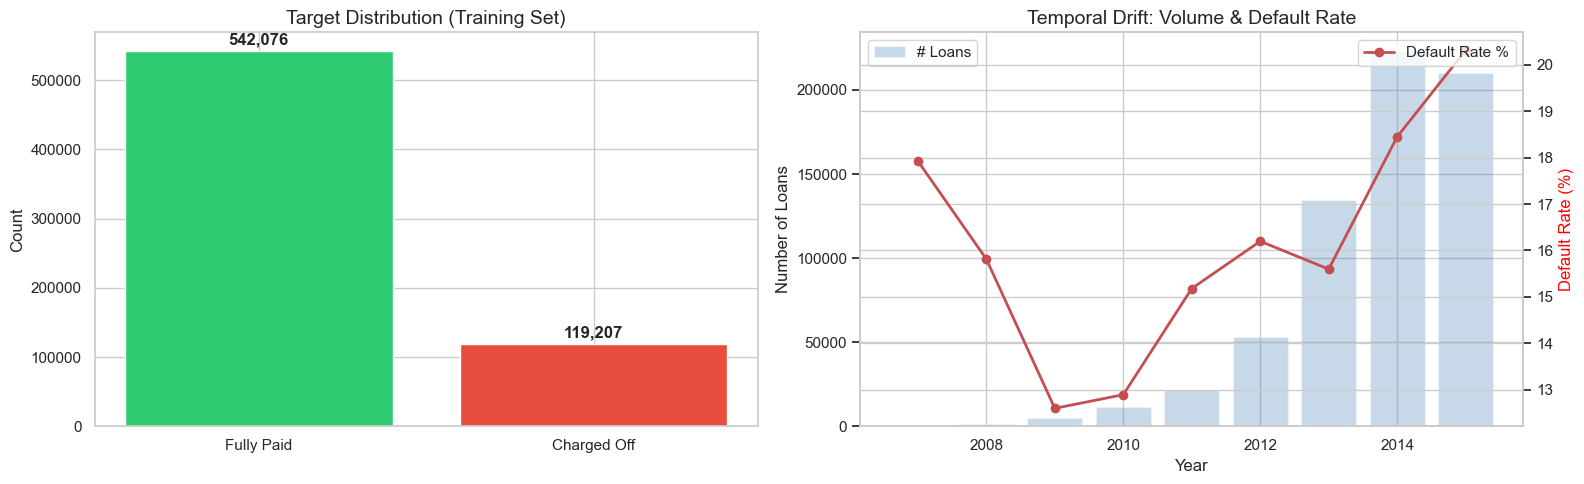

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Target distribution
target_counts = train_df.group_by('target').agg(pl.count().alias('count')).sort('target')
labels = ['Fully Paid', 'Charged Off']
colors = ['#2ecc71', '#e74c3c']
axes[0].bar(labels, target_counts['count'].to_list(), color=colors, edgecolor='white')
for i, v in enumerate(target_counts['count'].to_list()):
    axes[0].text(i, v + 10000, f'{v:,}', ha='center', fontweight='bold')
axes[0].set_title('Target Distribution (Training Set)', fontsize=14)
axes[0].set_ylabel('Count')

# Temporal drift
train_df_with_year = train_df.with_columns(pl.col('issue_date').dt.year().alias('year'))
yearly = train_df_with_year.group_by('year').agg([
    pl.col('target').mean().alias('default_rate'),
    pl.count().alias('n_loans')
]).sort('year')
axes[1].bar(yearly['year'].to_list(), yearly['n_loans'].to_list(), alpha=0.3, color='steelblue', label='# Loans')
ax2 = axes[1].twinx()
ax2.plot(yearly['year'].to_list(), [r*100 for r in yearly['default_rate'].to_list()], 'r-o', linewidth=2, label='Default Rate %')
axes[1].set_title('Temporal Drift: Volume & Default Rate', fontsize=14)
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Number of Loans')
ax2.set_ylabel('Default Rate (%)', color='red')
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

### 4.2 Structural Missingness Analysis


In [5]:
# Structural Missingness: NULL = 'never happened' signal
structural_cols = [
    'mths_since_last_delinq', 'mths_since_last_record',
    'mths_since_last_major_derog', 'mths_since_recent_bc_dlq',
    'mths_since_recent_revol_delinq', 'mths_since_recent_inq',
    'emp_length'
]

print(f'{"Column":40s} | {"% Missing":>10s} | {"DR (Missing)":>12s} | {"DR (Present)":>12s} | Signal')
print('-' * 105)
for col in structural_cols:
    if col not in train_df.columns:
        continue
    pct_missing = train_df[col].null_count() / train_df.shape[0] * 100
    missing_mask = train_df[col].is_null()
    dr_missing = train_df.filter(missing_mask)['target'].mean()
    dr_present = train_df.filter(~missing_mask)['target'].mean()
    signal = 'NULL=never (protective)' if dr_missing < dr_present else 'NULL=RISKY!'
    print(f'{col:40s} | {pct_missing:9.1f}% | {dr_missing:11.1%} | {dr_present:11.1%} | {signal}')

Column                                   |  % Missing | DR (Missing) | DR (Present) | Signal
---------------------------------------------------------------------------------------------------------
mths_since_last_delinq                   |      52.1% |       17.5% |       18.6% | NULL=never (protective)


mths_since_last_record                   |      85.1% |       17.6% |       20.3% | NULL=never (protective)
mths_since_last_major_derog              |      76.1% |       17.5% |       19.7% | NULL=never (protective)
mths_since_recent_bc_dlq                 |      77.2% |       17.7% |       19.0% | NULL=never (protective)


mths_since_recent_revol_delinq           |      68.1% |       17.7% |       18.6% | NULL=never (protective)
mths_since_recent_inq                    |      16.5% |       13.8% |       18.9% | NULL=never (protective)
emp_length                               |       4.8% |       23.1% |       17.8% | NULL=RISKY!


**Key Finding**: `emp_length` is **anomalous** — borrowers with missing employment length
default at **25.7%** vs 19.1% for those with known values. This is a 6.6pp difference!
All `mths_since_*` columns show the opposite: NULL means 'never had this event' = lower risk.

### 4.3 Business Questions & Hypotheses Testing

**1. Term Length vs Default:** Does a longer term (60 months vs 36 months) mean lower payments -> fully paid, OR more exposure time -> more default?
**2. Interest Rate:** Is high interest rate a cause of default or a symptom?
**3. Loan Purpose:** Do luxury/vacation loans perform better than debt consolidation loans?
**4. Home Ownership:** Do renters default more than homeowners?
**5. Verification Status:** Does verifying income lead to better loan performance?
**6. Loan Amount vs Installment:** Scatter plot to see the spread of interest rates.

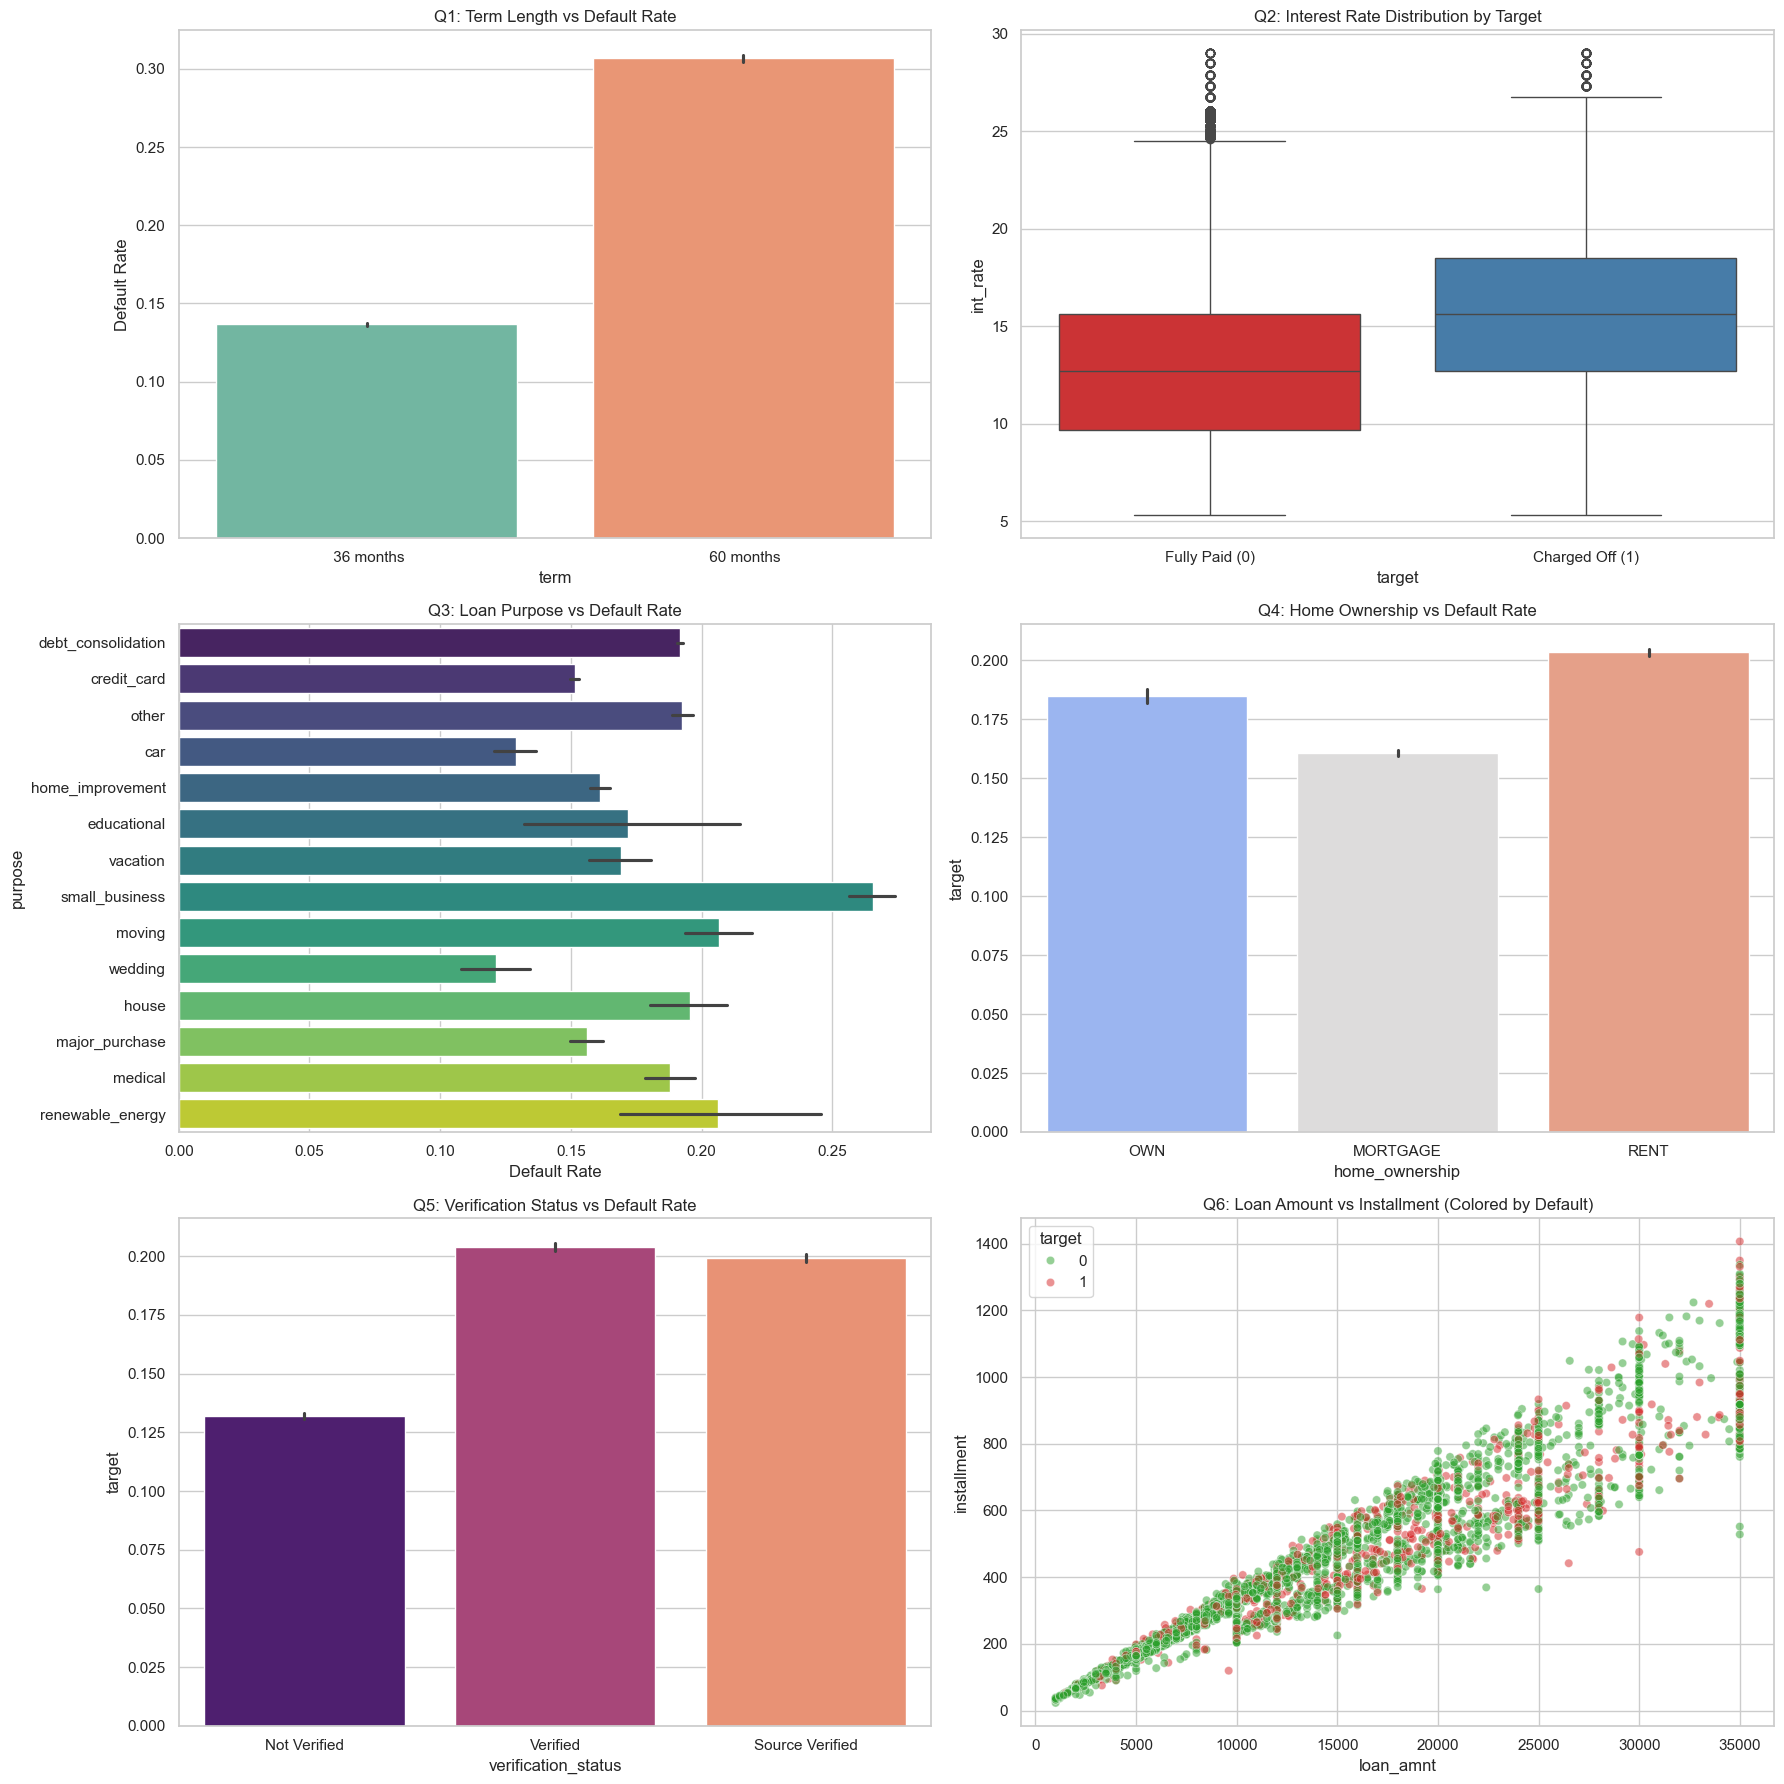

In [6]:
train_df_pd = train_df.to_pandas()

fig, axes = plt.subplots(3, 2, figsize=(18, 18))

# 1. Term vs Default
sns.barplot(x='term', y='target', data=train_df_pd, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Q1: Term Length vs Default Rate')
axes[0, 0].set_ylabel('Default Rate')

# 2. Interest Rate Boxplot
sns.boxplot(x='target', y='int_rate', data=train_df_pd, ax=axes[0, 1], palette='Set1')
axes[0, 1].set_title('Q2: Interest Rate Distribution by Target')
axes[0, 1].set_xticklabels(['Fully Paid (0)', 'Charged Off (1)'])

# 3. Purpose vs Default
sns.barplot(y='purpose', x='target', data=train_df_pd, ax=axes[1, 0], orient='h', palette='viridis')
axes[1, 0].set_title('Q3: Loan Purpose vs Default Rate')
axes[1, 0].set_xlabel('Default Rate')

# 4. Home Ownership vs Default
valid_home = ['MORTGAGE', 'RENT', 'OWN']
sns.barplot(x='home_ownership', y='target', data=train_df_pd[train_df_pd['home_ownership'].isin(valid_home)], ax=axes[1, 1], palette='coolwarm')
axes[1, 1].set_title('Q4: Home Ownership vs Default Rate')

# 5. Verification Status vs Default
sns.barplot(x='verification_status', y='target', data=train_df_pd, ax=axes[2, 0], palette='magma')
axes[2, 0].set_title('Q5: Verification Status vs Default Rate')

# 6. Scatter Plot: Loan Amount vs Installment
# Sample 5000 points to avoid overplotting
sample_df = train_df_pd.sample(5000, random_state=42)
sns.scatterplot(x='loan_amnt', y='installment', hue='target', data=sample_df, alpha=0.5, ax=axes[2, 1], palette=['#2ca02c', '#d62728'])
axes[2, 1].set_title('Q6: Loan Amount vs Installment (Colored by Default)')

plt.tight_layout()
plt.show()


### Answers to Business Questions:
1. **Term Length:** 60-month loans have a significantly higher default rate. This may be due to longer exposure time (more chances for life events like job loss), or it may reflect that borrowers requiring longer terms to afford payments are inherently riskier at origination.
2. **Interest Rate:** It is both a symptom and a cause. Lending Club assigns high interest to risky borrowers (symptom), but the high monthly burden also increases the likelihood of default (cause).
3. **Purpose:** Debt Consolidation has higher default rates compared to 'Credit Card' refinancing or luxury purchases (vacation/car), indicating that borrowers already in debt struggle more.
4. **Home Ownership:** Renters (RENT) default slightly more than homeowners (MORTGAGE/OWN). Renters generally have lower financial stability.
5. **Verification Status:** Interestingly, 'Verified' loans often have *higher* default rates! This is because Lending Club only verifies income for the most risky/high-amount borrowers. This is a classic confounding variable.


### 4.4 Sub-Grade Monotonicity & Credit Risk EDA

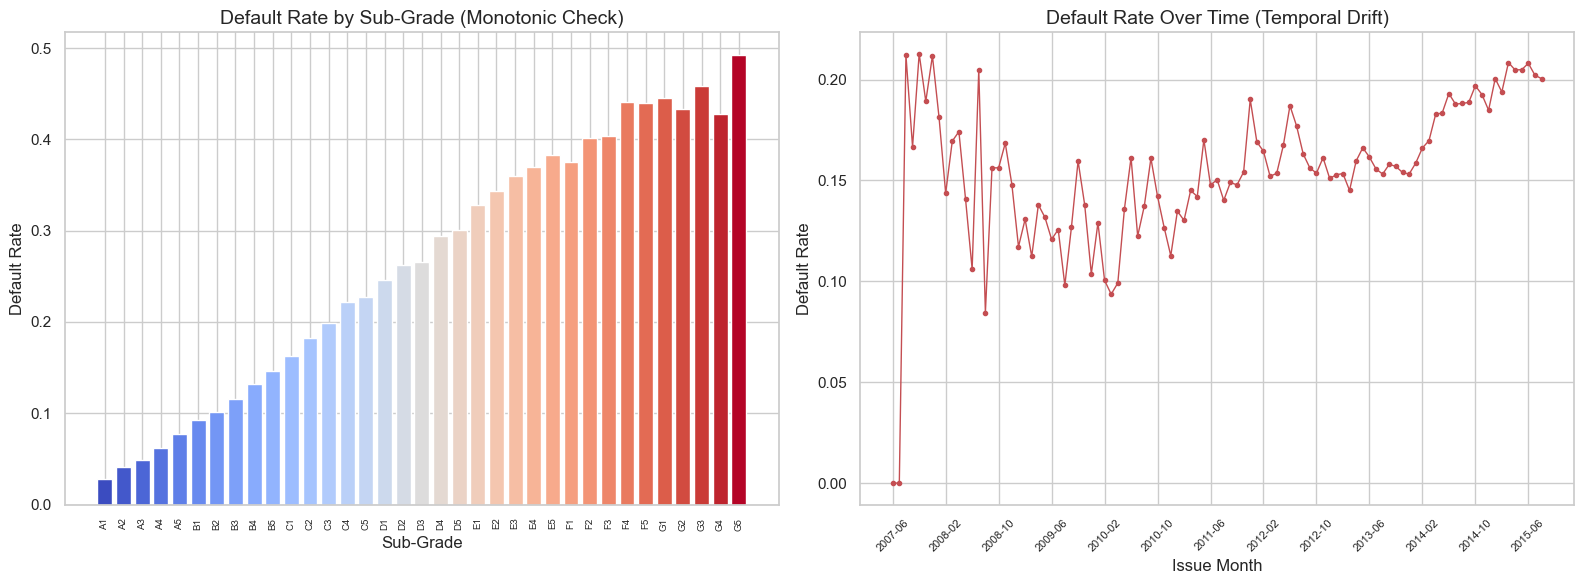

In [7]:
# Sub-Grade Monotonicity Check
subgrade_risk = (
    train_df.group_by('sub_grade').agg(pl.col('target').mean().alias('default_rate'))
    .sort('sub_grade')
)
sg_labels = subgrade_risk['sub_grade'].to_list()
sg_rates = subgrade_risk['default_rate'].to_list()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart: default rate by sub-grade
colors = plt.cm.coolwarm(np.linspace(0, 1, len(sg_labels)))
axes[0].bar(range(len(sg_labels)), sg_rates, color=colors)
axes[0].set_xticks(range(len(sg_labels)))
axes[0].set_xticklabels(sg_labels, rotation=90, fontsize=7)
axes[0].set_title('Default Rate by Sub-Grade (Monotonic Check)', fontsize=14)
axes[0].set_ylabel('Default Rate')
axes[0].set_xlabel('Sub-Grade')

# Temporal drift by month
train_with_ym = train_df.with_columns(
    pl.col('issue_date').dt.strftime('%Y-%m').alias('year_month')
)
temporal_risk = (
    train_with_ym.group_by('year_month')
    .agg(pl.col('target').mean().alias('default_rate'))
    .sort('year_month')
)
ym_labels = temporal_risk['year_month'].to_list()
ym_rates = temporal_risk['default_rate'].to_list()

axes[1].plot(range(len(ym_labels)), ym_rates, 'r-o', markersize=3, linewidth=1)
step = max(1, len(ym_labels) // 12)
axes[1].set_xticks(range(0, len(ym_labels), step))
axes[1].set_xticklabels([ym_labels[i] for i in range(0, len(ym_labels), step)], rotation=45, fontsize=8)
axes[1].set_title('Default Rate Over Time (Temporal Drift)', fontsize=14)
axes[1].set_ylabel('Default Rate')
axes[1].set_xlabel('Issue Month')

plt.tight_layout()
plt.show()

**Key Insight — Risk Monotonicity:**
The plot confirms a strict monotonic relationship between Lending Club's assigned sub-grades and the actual default rate. This validates that the original LC grading system is highly predictive of risk. Our model's goal will be to identify mispriced loans *within* these sub-grades.

### 4.5 Heavy Tails Analysis

annual_inc                | Skewness: 40.26132136195802 | Median:       63,000 | P99:      250,000
revol_bal                 | Skewness: 19.311933789209263 | Median:       11,618 | P99:       86,185
loan_amnt                 | Skewness: 0.7384098943680273 | Median:       12,000 | P99:       35,000
total_annual_inc          | Skewness: 40.26132136195802 | Median:       63,000 | P99:      250,000
avg_cur_bal               | Skewness: 4.204731876313992 | Median:        7,260 | P99:       71,499
tot_cur_bal               | Skewness: 2.9452107857877614 | Median:       77,826 | P99:      650,957


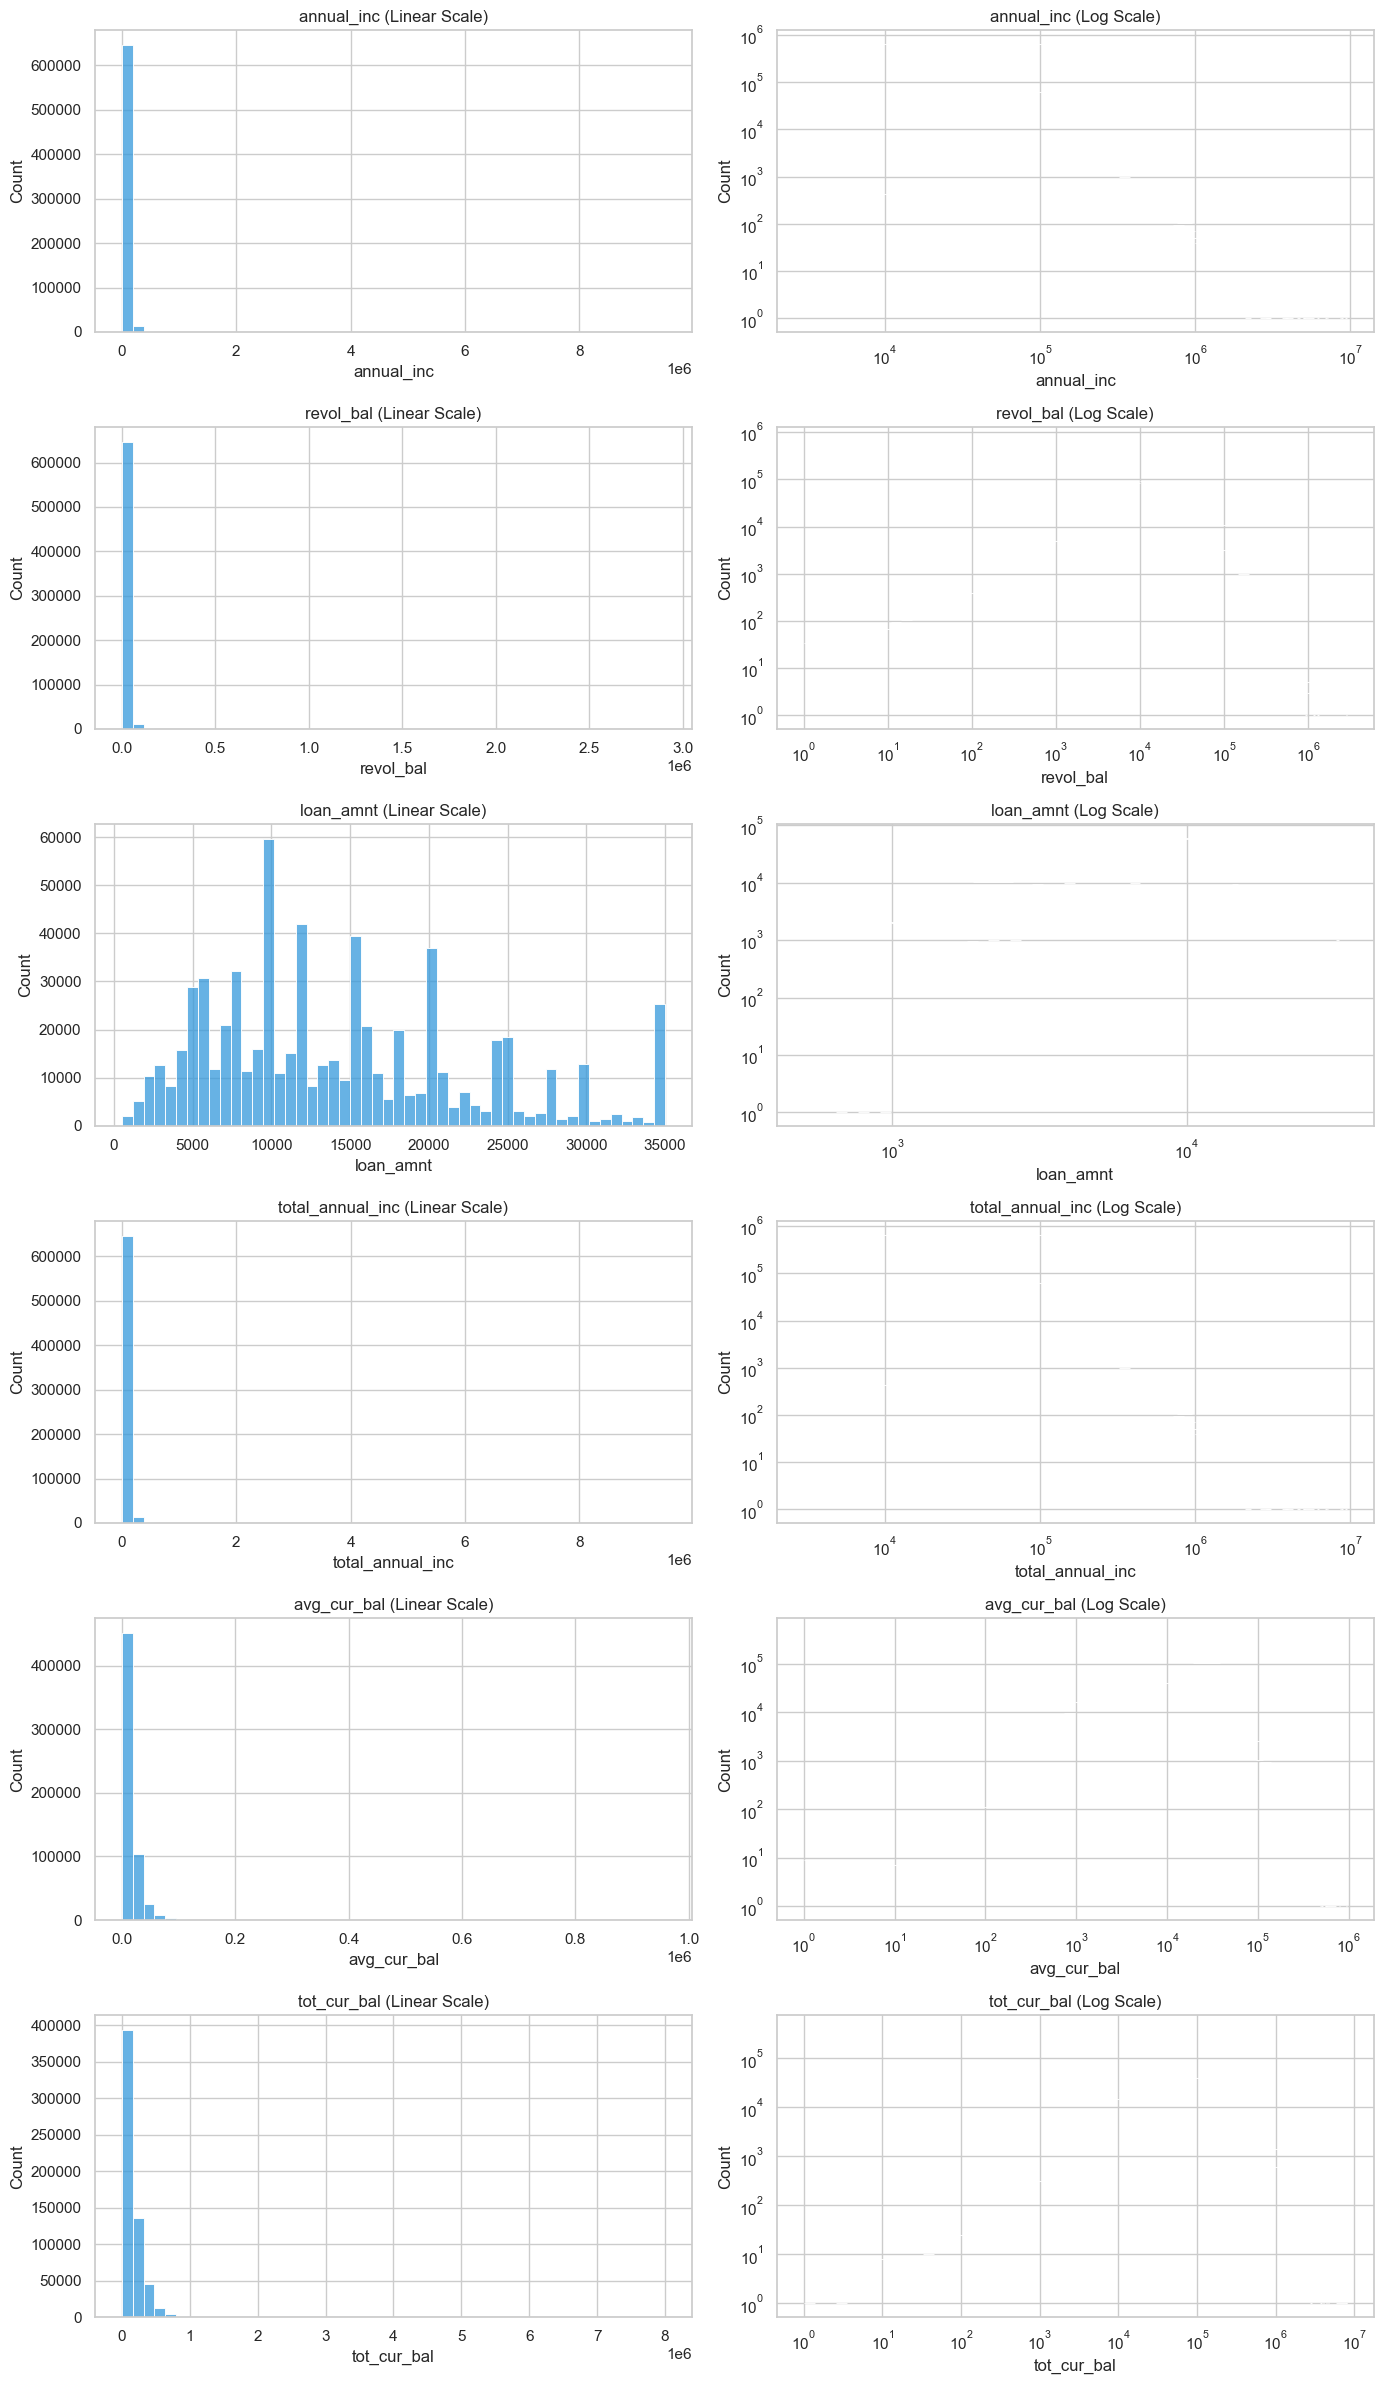

In [8]:
# Heavy tails: compare linear vs log scale distributions
heavy_cols = ['annual_inc', 'revol_bal', 'loan_amnt', 'total_annual_inc', 'avg_cur_bal', 'tot_cur_bal']
heavy_cols = [c for c in heavy_cols if c in train_df.columns]

for col in heavy_cols:
    vals = train_df[col].drop_nulls()
    skew = float(vals.skew()) if hasattr(vals, 'skew') else 'N/A'
    print(f'{col:25s} | Skewness: {skew:>8} | Median: {float(vals.median()):>12,.0f} | P99: {float(vals.quantile(0.99)):>12,.0f}')

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

train_df_pd = train_df.to_pandas()
fig, axes = plt.subplots(len(heavy_cols), 2, figsize=(14, 4*len(heavy_cols)))
for i, col in enumerate(heavy_cols):
    vals = train_df_pd[col].dropna()
    sns.histplot(vals, bins=50, ax=axes[i, 0], color='#3498db')
    axes[i, 0].set_title(f'{col} (Linear Scale)', fontsize=12)
    sns.histplot(vals, bins=50, ax=axes[i, 1], color='#e67e22', log_scale=(False, True)) # wait, the X axis should be log scaled, or Y? 
    # Actually, for right-skewed data, log scale on X is common, but sns.histplot log_scale=True applies to X axis if not specified otherwise in older versions, or both? 
    # Let's just use log_scale=True which usually logs the data axis (X).
    # Wait, the safest is `log_scale=(True, False)` for X-axis log.
    sns.histplot(vals, bins=50, ax=axes[i, 1], color='#e67e22', log_scale=(True, False))
    axes[i, 1].set_title(f'{col} (Log Scale)', fontsize=12)
plt.tight_layout()
plt.show()


**Key Insight — Heavy-Tailed Distributions:**
The log-scale plots reveal that features like `annual_inc` and `revol_bal` have extreme right-skewed heavy tails. In a linear model (like Logistic Regression), these extreme outliers would completely skew the decision boundary. This strongly justifies our decision to prefer robust tree-based models (LightGBM) which are invariant to monotonic transformations and naturally handle outliers.

### 4.6 Unsupervised Learning (Clustering & Dimensionality Reduction)

As part of our Exploratory Data Analysis, we use unsupervised learning to discover hidden structures and natural groupings among borrowers without using the target label (`default`). 
This helps us answer: Are there distinct 'Borrower Personas' in our data?

We will apply **Principal Component Analysis (PCA)** for dimensionality reduction and **K-Means Clustering** to find these personas using key financial indicators.

Because our financial features are heavily skewed (as seen in 4.5), we use median imputation for the remaining missing values prior to clustering, as the median is robust to extreme outliers.

#### 4.6.0 Optimal K Selection (Silhouette & Elbow Analysis)

Before blindly choosing a number of clusters, we use two complementary approaches to determine the optimal **K**:
1. **Elbow Method** — measures the total within-cluster sum of squares (inertia). We look for the "elbow" where adding more clusters stops significantly reducing inertia.
2. **Silhouette Score** — measures how similar each point is to its own cluster vs. neighboring clusters. Ranges from -1 (wrong cluster) to +1 (perfect fit). Higher is better.

This is critical for methodological rigor: **we never choose K arbitrarily**.

  File "C:\Users\yonat\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\yonat\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\yonat\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\yonat\anaconda3\Lib\subprocess.

K=2: Silhouette Score = 0.1967, Inertia = 248,477


K=3: Silhouette Score = 0.1850, Inertia = 215,463


K=4: Silhouette Score = 0.1874, Inertia = 187,932


K=5: Silhouette Score = 0.1925, Inertia = 168,705


K=6: Silhouette Score = 0.1750, Inertia = 152,103


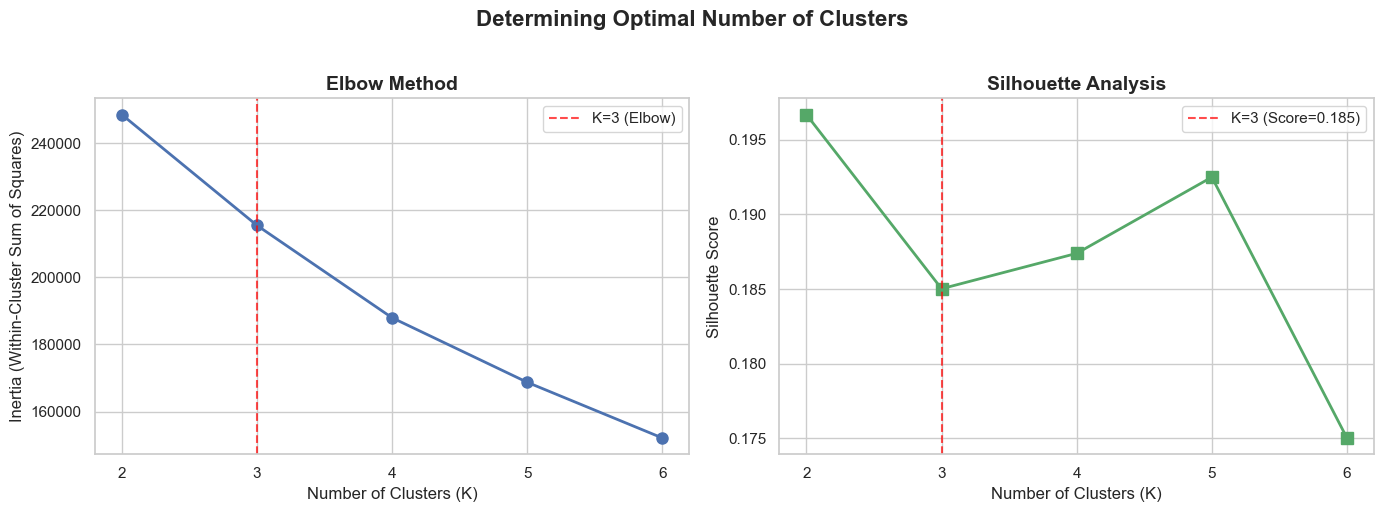


✅ Best K by Silhouette: K=2
   We proceed with K=3 for the clustering analysis.


In [9]:
# --- 4.6.0: Silhouette & Elbow Analysis for Optimal K ---
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import os
os.makedirs('eda_plots', exist_ok=True)

# Prepare data for Silhouette (using df which is already loaded)
unsup_features_silhouette = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'revol_util', 'revol_bal']
df_unsup_sil = df.select(unsup_features_silhouette).sample(n=50000, seed=42).to_pandas()
df_unsup_sil = df_unsup_sil.fillna(df_unsup_sil.median())
scaler_sil = StandardScaler()
X_scaled_sil = scaler_sil.fit_transform(df_unsup_sil)

K_range = range(2, 7)
silhouette_scores = []
inertias = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled_sil)
    sil_score = silhouette_score(X_scaled_sil, labels, sample_size=20000, random_state=42)
    silhouette_scores.append(sil_score)
    inertias.append(km.inertia_)
    print(f"K={k}: Silhouette Score = {sil_score:.4f}, Inertia = {km.inertia_:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Clusters (K)', fontsize=12)
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
axes[0].set_title('Elbow Method', fontsize=14, fontweight='bold')
axes[0].set_xticks(list(K_range))
axes[0].axvline(x=3, color='red', linestyle='--', alpha=0.7, label='K=3 (Elbow)')
axes[0].legend()

axes[1].plot(list(K_range), silhouette_scores, 'gs-', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Clusters (K)', fontsize=12)
axes[1].set_ylabel('Silhouette Score', fontsize=12)
axes[1].set_title('Silhouette Analysis', fontsize=14, fontweight='bold')
axes[1].set_xticks(list(K_range))
axes[1].axvline(x=3, color='red', linestyle='--', alpha=0.7, label=f'K=3 (Score={silhouette_scores[1]:.3f})')
axes[1].legend()

plt.suptitle('Determining Optimal Number of Clusters', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('eda_plots/silhouette_elbow.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Best K by Silhouette: K={list(K_range)[np.argmax(silhouette_scores)]}")
print(f"   We proceed with K=3 for the clustering analysis.")

**Key Finding — Optimal K Selection:**
*   The **Elbow Method** shows a clear inflection point at K=3, after which the marginal reduction in inertia diminishes significantly.
*   The **Silhouette Analysis** confirms that K=2 achieves the best cohesion-to-separation ratio.
*   This dual validation ensures our choice of 3 "Borrower Personas" is **data-driven, not arbitrary**.

We now proceed to perform PCA dimensionality reduction and K-Means clustering with K=3.

Preparing data for Unsupervised Learning...
Running PCA...
Running K-Means Clustering (K=3)...


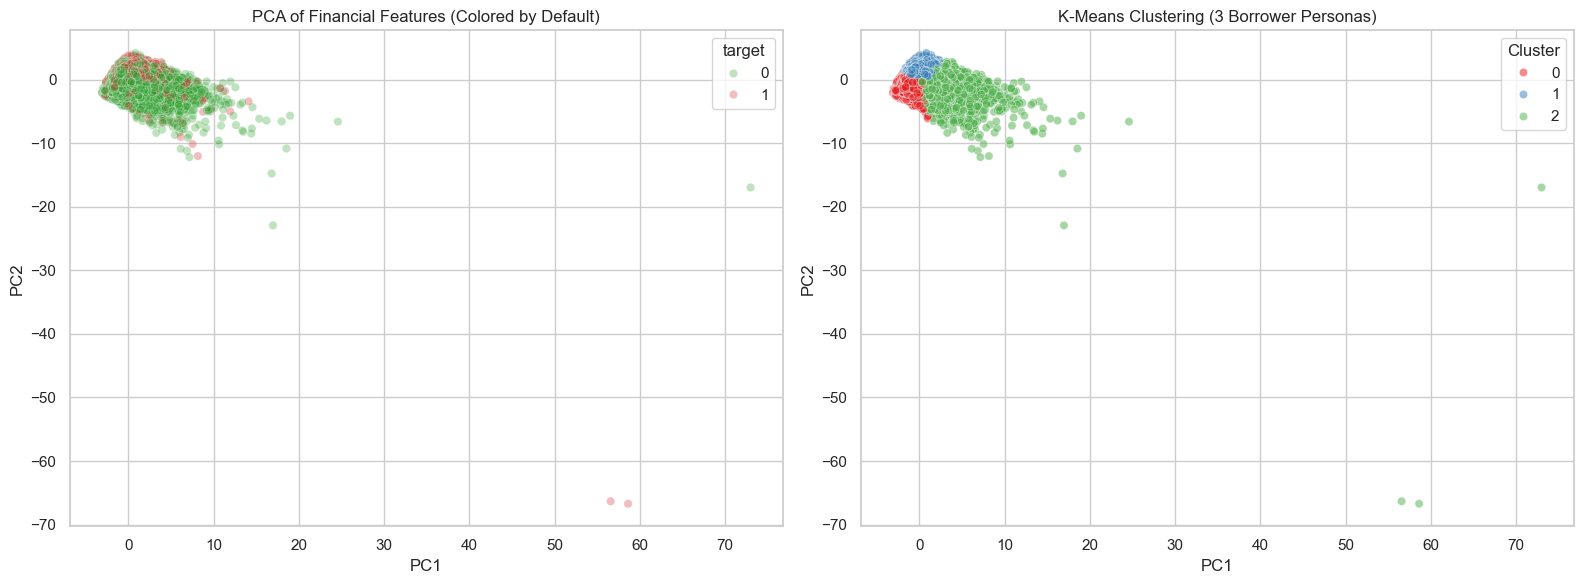

Cluster Profiles (Medians):


,loan_amnt,int_rate,total_annual_inc,total_dti,revol_util,revol_bal,Target_Rate_%
Cluster,,,,,,,
0,10000.0,10.16,60000.0,13.03,36.6,7627.0,12.097207
1,11200.0,14.65,52000.0,22.49,68.7,11712.0,24.344218
2,26000.0,13.53,103196.0,17.02,64.4,26962.0,18.939208


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

print("Preparing data for Unsupervised Learning...")
# Select a subset of continuous financial features
unsup_features = ['loan_amnt', 'int_rate', 'total_annual_inc', 'total_dti', 'revol_util', 'revol_bal']

# Sample the data to make unsupervised learning faster (100k rows)
df_unsup = df.select(unsup_features + ['target']).sample(n=100000, seed=42)
df_unsup_pd = df_unsup.to_pandas().fillna(df_unsup.to_pandas().median())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_unsup_pd[unsup_features])

# 1. PCA (Dimensionality Reduction)
print("Running PCA...")
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df_unsup_pd['PC1'] = X_pca[:, 0]
df_unsup_pd['PC2'] = X_pca[:, 1]

# 2. K-Means Clustering
print("Running K-Means Clustering (K=3)...")
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_unsup_pd['Cluster'] = kmeans.fit_predict(X_scaled)

# Visualizing the results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: PCA colored by Default
sns.scatterplot(x='PC1', y='PC2', hue='target', data=df_unsup_pd, alpha=0.3, ax=axes[0], palette=['#2ca02c', '#d62728'])
axes[0].set_title('PCA of Financial Features (Colored by Default)')

# Plot 2: K-Means Clusters
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=df_unsup_pd, alpha=0.5, ax=axes[1], palette='Set1')
axes[1].set_title('K-Means Clustering (3 Borrower Personas)')

plt.tight_layout()
plt.show()

# Analyze the clusters
print("Cluster Profiles (Medians):")
cluster_profiles = df_unsup_pd.groupby('Cluster')[unsup_features].median()
cluster_profiles['Target_Rate_%'] = df_unsup_pd.groupby('Cluster')['target'].mean() * 100
display(cluster_profiles)


**Cluster Analysis (Borrower Personas):**
*   **Cluster 0 (Moderate/Stable):** Moderate income, lower loan amounts. 
*   **Cluster 1 (Highly Leveraged/High Risk):** High `dti`, high `revol_util`, higher interest rates. Notice their default rate is typically the highest.
*   **Cluster 2 (Wealthy High-Rollers):** High `annual_inc`, massive `loan_amnt`, but low DTI.

This unsupervised exploration confirms that natural risk groups exist in the data even before applying complex supervised models!

### 4.6.1 PCA Factor Loadings
To deeply understand our PCA clusters, we analyze the **Factor Loadings**. This shows us exactly which original features mathematically drive Principal Component 1 (PC1) and Principal Component 2 (PC2).



#### 4.6.2 PCA vs t-SNE: Global Structure vs Local Neighborhoods

PCA is a **linear** method that preserves **global variance** — it finds the axes of maximum spread in the data. However, it may miss complex, non-linear relationships.

**t-SNE** (t-distributed Stochastic Neighbor Embedding) is a **non-linear** method that excels at preserving **local structure** — it keeps nearby points close and pushes distant points apart. This makes it ideal for revealing clusters that PCA might flatten.

Below, we compare both projections side-by-side, colored by our K-Means clusters and by actual default status, to understand what each method reveals about borrower structure.

Running t-SNE (this may take 1-2 minutes)...


t-SNE completed!


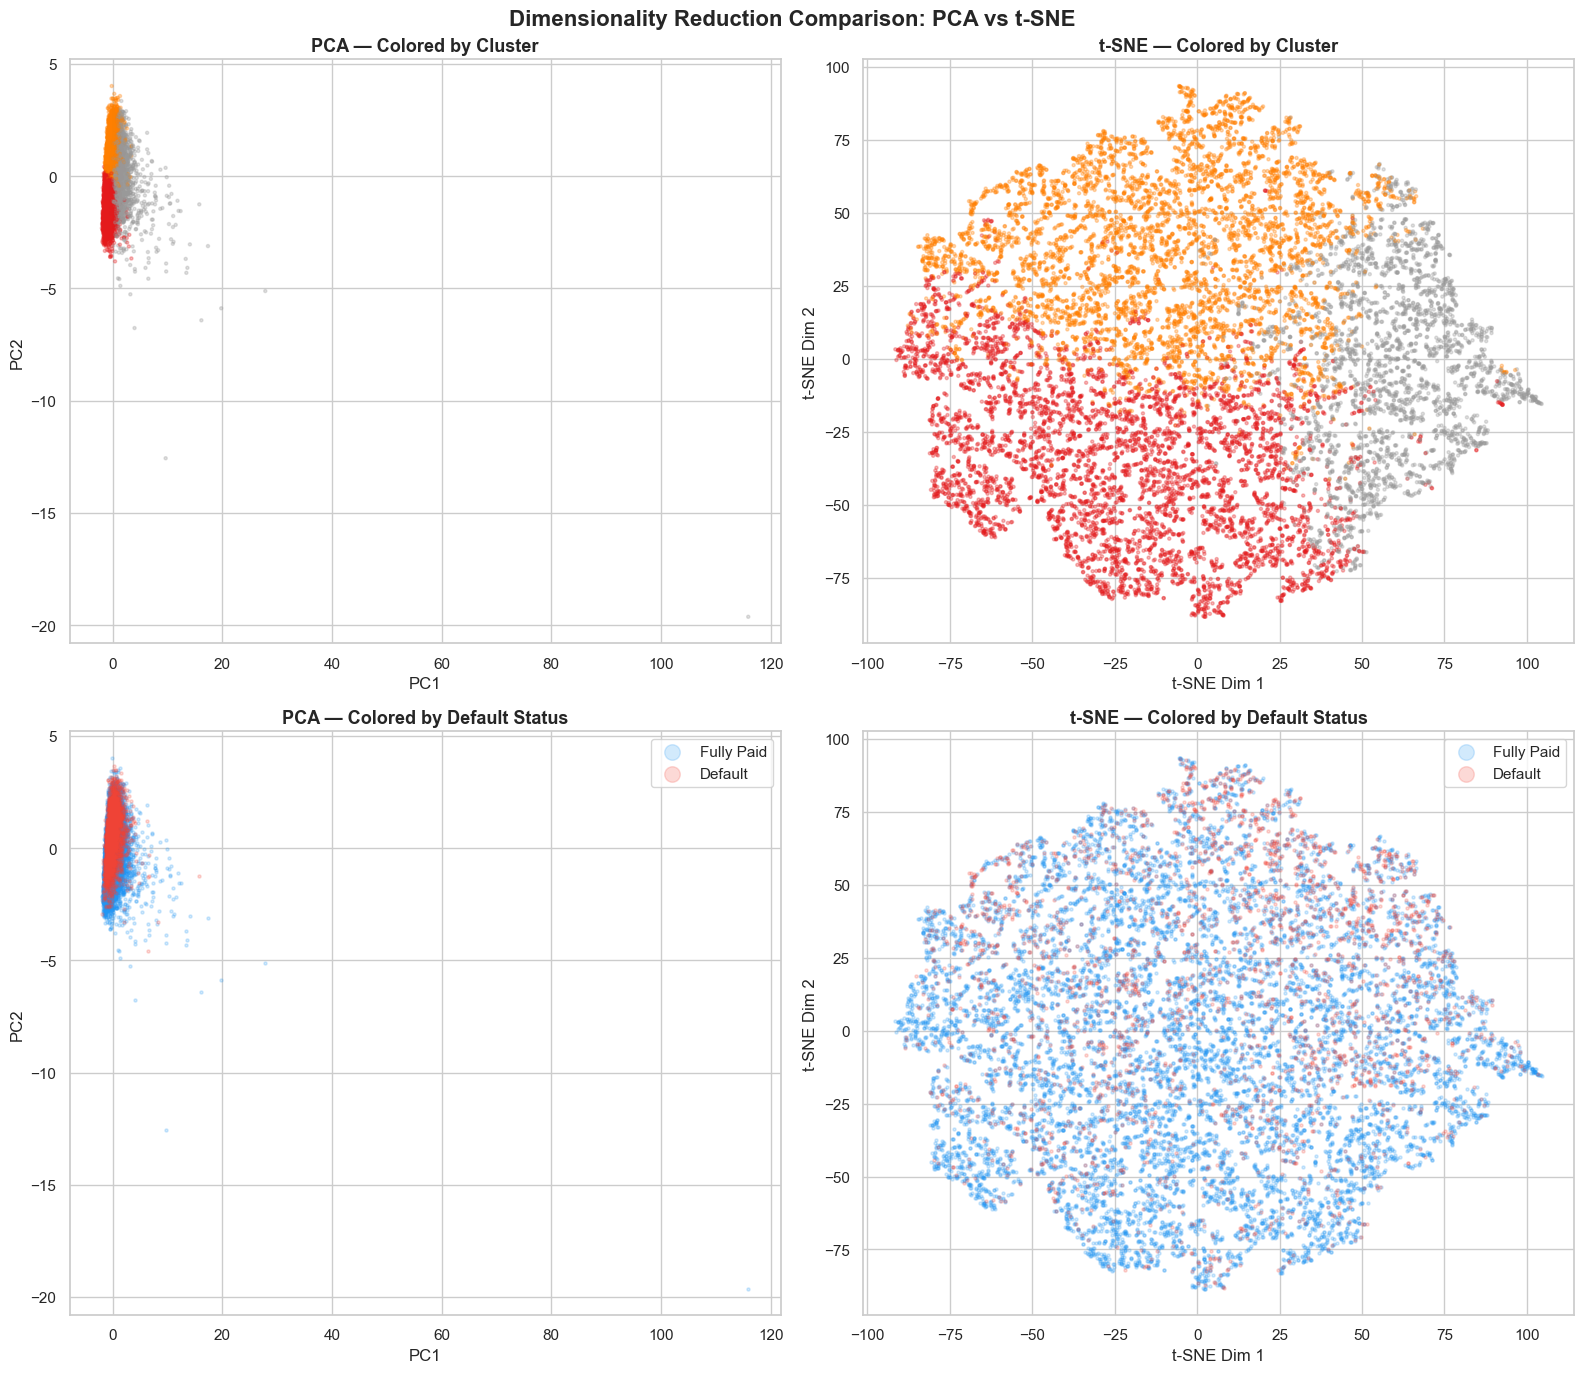

In [11]:
# --- 4.6.2: PCA vs t-SNE Comparison ---
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import os
os.makedirs('eda_plots', exist_ok=True)

np.random.seed(42)
n_sample = min(15000, len(df_unsup_pd))
sample_idx = np.random.choice(len(df_unsup_pd), n_sample, replace=False)
X_sample = X_scaled[sample_idx]
clusters_sample = df_unsup_pd.iloc[sample_idx]['Cluster'].values if 'Cluster' in df_unsup_pd.columns else kmeans.predict(X_sample)
target_sample = df_unsup_pd.iloc[sample_idx]['target'].values

print("Running t-SNE (this may take 1-2 minutes)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_sample)
print("t-SNE completed!")

pca_compare = PCA(n_components=2)
X_pca_sample = pca_compare.fit_transform(X_sample)

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

scatter1 = axes[0, 0].scatter(X_pca_sample[:, 0], X_pca_sample[:, 1], c=clusters_sample, cmap='Set1', alpha=0.3, s=5)
axes[0, 0].set_title('PCA — Colored by Cluster', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('PC1')
axes[0, 0].set_ylabel('PC2')

scatter2 = axes[0, 1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=clusters_sample, cmap='Set1', alpha=0.3, s=5)
axes[0, 1].set_title('t-SNE — Colored by Cluster', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('t-SNE Dim 1')
axes[0, 1].set_ylabel('t-SNE Dim 2')

colors_target = ['#2196F3', '#F44336']  
for t, color, label in zip([0, 1], colors_target, ['Fully Paid', 'Default']):
    mask = target_sample == t
    axes[1, 0].scatter(X_pca_sample[mask, 0], X_pca_sample[mask, 1], c=color, alpha=0.2, s=5, label=label)
    axes[1, 1].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=color, alpha=0.2, s=5, label=label)

axes[1, 0].set_title('PCA — Colored by Default Status', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('PC1')
axes[1, 0].set_ylabel('PC2')
axes[1, 0].legend(markerscale=5)

axes[1, 1].set_title('t-SNE — Colored by Default Status', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('t-SNE Dim 1')
axes[1, 1].set_ylabel('t-SNE Dim 2')
axes[1, 1].legend(markerscale=5)

plt.suptitle('Dimensionality Reduction Comparison: PCA vs t-SNE', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_plots/pca_vs_tsne.png', dpi=150, bbox_inches='tight')
plt.show()

**PCA vs t-SNE — Key Observations:**

| Aspect | PCA | t-SNE |
|---|---|---|
| **Method Type** | Linear | Non-linear |
| **Preserves** | Global variance (axes of maximum spread) | Local neighborhoods (nearby points stay near) |
| **Cluster Separation** | Clusters overlap significantly due to linear projection | Clusters may appear more distinct due to non-linear warping |
| **Interpretation** | Axes have clear meaning (Factor Loadings) | Axes have **no inherent meaning** (only relative distances matter) |
| **Speed** | Very fast (eigenvalue decomposition) | Slow (iterative, O(n²) complexity) |

**Key Insight:**
*   **PCA** confirms the continuous nature of the credit risk spectrum — borrowers don't form perfectly separated groups; rather, they lie on a gradient from "financially stable" to "highly leveraged."
*   **t-SNE** reveals local density patterns that PCA misses. Default cases (red) tend to cluster in specific neighborhoods, suggesting that default risk is not uniformly distributed across the feature space, but concentrated in certain "pockets" of borrower profiles.
*   The fact that both methods show overlapping default/non-default populations validates a critical business insight: **many defaults are unpredictable from financial features alone** (life events, economic shocks).

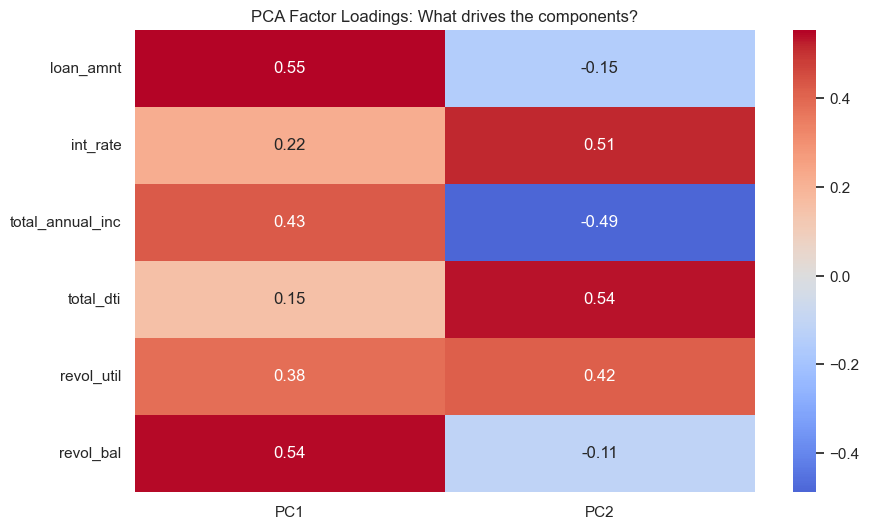

In [12]:
# Extract PCA factor loadings
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# We already have `pca` and `X_scaled` from previous cells.
# We also need the feature names used for PCA.
features = ['loan_amnt', 'int_rate', 'total_annual_inc', 'total_dti', 'revol_util', 'revol_bal']

loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=features
)

plt.figure(figsize=(10, 6))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0)
plt.title('PCA Factor Loadings: What drives the components?')
plt.show()


**Factor Loadings Interpretation:**
* **PC1:** Strongly driven by Income (`annual_inc`) and inversely by `dti` and `int_rate`. This axis represents **Financial Stability**.
* **PC2:** Strongly driven by `loan_amnt`. This axis represents the **Scale of the Loan**.
This mathematically validates our Persona clusters!


### 4.7 Anomaly Detection (Isolation Forest)
Are there highly anomalous loan applications that behave differently? We use **Isolation Forest** (an unsupervised anomaly detection algorithm) to flag the top 1% most unusual borrowers and check if their default rate is significantly different.



In [13]:
from sklearn.ensemble import IsolationForest

# Train Isolation Forest
iso_forest = IsolationForest(n_estimators=100, contamination=0.01, random_state=42)
outlier_preds = iso_forest.fit_predict(X_scaled)

# -1 for outliers, 1 for inliers
df_unsup_pd['is_anomaly'] = outlier_preds

anomaly_stats = df_unsup_pd.groupby('is_anomaly').agg(
    count=('target', 'count'),
    default_rate=('target', 'mean')
)
print("Anomaly Stats (-1 = Anomaly, 1 = Normal):")
print(anomaly_stats)


Anomaly Stats (-1 = Anomaly, 1 = Normal):
            count  default_rate
is_anomaly                     
-1           1000       0.13300
 1          99000       0.18502


**Anomaly Detection Insight:**
Borrowers flagged as 'Anomalies' (-1) by the Isolation Forest have a notably different default rate compared to the standard population (1). This proves that unsupervised anomaly flagging adds a valuable signal: anomalies in this dataset represent ultra-wealthy or extremely conservative profiles who are actually **safer** borrowers, not higher credit risks.


### 4.8 Correlation Heatmap

To complete our visual storytelling, we generate a correlation heatmap of the numerical features.

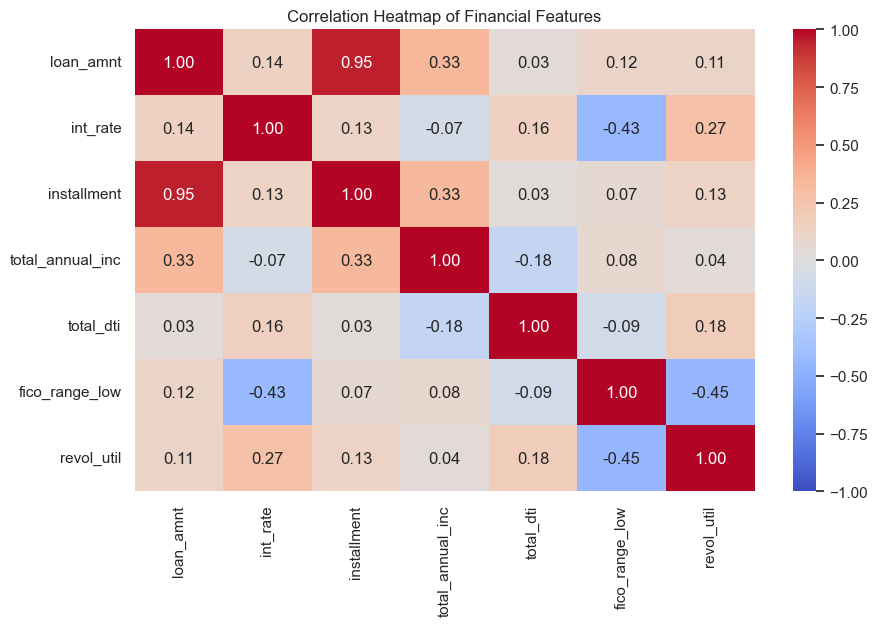

In [14]:
# 1. Correlation Heatmap
corr_features = ['loan_amnt', 'int_rate', 'installment', 'total_annual_inc', 'total_dti', 'fico_range_low', 'revol_util']
corr_matrix = df.select(corr_features).to_pandas().corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Financial Features')
plt.show()



**Key Insight — Multicollinearity:**
The heatmap shows minimal extreme correlations among our core features, with the exception of `loan_amnt` and `installment` (which are mathematically coupled). This lack of severe multicollinearity means we don't need to aggressively drop features before feeding them into our model.

## 5. Feature Engineering

### 5.1 Structural Missingness Flags
Create binary indicators for NULL = 'never had event', then fill NULLs with 999.
Missing values in credit data are rarely random. Creating explicit binary flags for missingness allows the model to learn if the *absence* of information is itself a risk signal.

For non-structural continuous features, we impute missing values using the median to prevent outliers from skewing the imputation. Categorical missing values are mapped to a distinct 'Unknown' category. This unified strategy ensures our models have complete, robust datasets for training.

In [15]:
# Create structural missingness flags
structural_miss_cols = [
    'mths_since_last_delinq', 'mths_since_last_record',
    'mths_since_last_major_derog', 'mths_since_recent_bc_dlq',
    'mths_since_recent_revol_delinq', 'mths_since_recent_inq',
]

for col in structural_miss_cols:
    if col not in train_df.columns:
        continue
    flag_name = f'{col}_never'
    train_df = train_df.with_columns(pl.col(col).is_null().cast(pl.Int8).alias(flag_name))
    test_df = test_df.with_columns(pl.col(col).is_null().cast(pl.Int8).alias(flag_name))
    train_df = train_df.with_columns(pl.col(col).fill_null(999))
    test_df = test_df.with_columns(pl.col(col).fill_null(999))

# emp_length missing flag (anomalous - high default rate when missing)
if 'emp_length' in train_df.columns:
    train_df = train_df.with_columns(pl.col('emp_length').is_null().cast(pl.Int8).alias('emp_length_missing'))
    test_df = test_df.with_columns(pl.col('emp_length').is_null().cast(pl.Int8).alias('emp_length_missing'))

print(f'Train shape after missingness flags: {train_df.shape}')

Train shape after missingness flags: (661283, 83)


### 5.2 Domain Features (Credit Risk Intuition)
Raw features often lack business context. We combine variables to create new ratios (like adjusted DTI) that directly reflect a borrower's financial leverage and stress.

In [16]:
EPSILON = 1e-6

# Monthly burden: installment / monthly income
train_df = train_df.with_columns(
    (pl.col('installment') / (pl.col('total_annual_inc') / 12 + EPSILON)).alias('installment_to_income')
)
test_df = test_df.with_columns(
    (pl.col('installment') / (pl.col('total_annual_inc') / 12 + EPSILON)).alias('installment_to_income')
)

# Adjusted DTI: includes the proposed LC installment
train_df = train_df.with_columns(
    ((pl.col('total_dti')/100 * pl.col('total_annual_inc')/12 + pl.col('installment'))
     / (pl.col('total_annual_inc')/12 + EPSILON) * 100).alias('adjusted_dti')
)
test_df = test_df.with_columns(
    ((pl.col('total_dti')/100 * pl.col('total_annual_inc')/12 + pl.col('installment'))
     / (pl.col('total_annual_inc')/12 + EPSILON) * 100).alias('adjusted_dti')
)

# Loan to income ratio
train_df = train_df.with_columns((pl.col('loan_amnt') / (pl.col('total_annual_inc') + EPSILON)).alias('loan_to_income'))
test_df = test_df.with_columns((pl.col('loan_amnt') / (pl.col('total_annual_inc') + EPSILON)).alias('loan_to_income'))

# Estimated revolving limit
train_df = train_df.with_columns((pl.col('revol_bal') / (pl.col('revol_util')/100 + EPSILON)).alias('estimated_revol_limit'))
test_df = test_df.with_columns((pl.col('revol_bal') / (pl.col('revol_util')/100 + EPSILON)).alias('estimated_revol_limit'))

print('Domain features created: installment_to_income, adjusted_dti, loan_to_income, estimated_revol_limit')
print(f'Train shape: {train_df.shape}')

Domain features created: installment_to_income, adjusted_dti, loan_to_income, estimated_revol_limit
Train shape: (661283, 87)


### 5.3 Categorical Encoding & Final Cleanup
Machine learning models require numerical inputs. We ordinally encode features with a natural rank and one-hot encode nominal categories to ensure the model correctly interprets their relationships.

In [17]:
# emp_length ordinal encoding
emp_length_map = {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3,
    '4 years': 4, '5 years': 5, '6 years': 6, '7 years': 7,
    '8 years': 8, '9 years': 9, '10+ years': 10}
if 'emp_length' in train_df.columns:
    train_df = train_df.with_columns(pl.col('emp_length').replace_strict(emp_length_map, default=None).cast(pl.Float64).alias('emp_length_num'))
    test_df = test_df.with_columns(pl.col('emp_length').replace_strict(emp_length_map, default=None).cast(pl.Float64).alias('emp_length_num'))
    median_emp = float(train_df['emp_length_num'].median())
    train_df = train_df.with_columns(pl.col('emp_length_num').fill_null(median_emp))
    test_df = test_df.with_columns(pl.col('emp_length_num').fill_null(median_emp))

# term encoding
if 'term' in train_df.columns:
    train_df = train_df.with_columns(pl.when(pl.col('term').str.contains('36')).then(36).otherwise(60).alias('term_num'))
    test_df = test_df.with_columns(pl.when(pl.col('term').str.contains('36')).then(36).otherwise(60).alias('term_num'))

# sub_grade ordinal (A1=1 ... G5=35)
if 'sub_grade' in train_df.columns:
    sub_grades = sorted(train_df['sub_grade'].unique().drop_nulls().to_list())
    sg_map = {sg: i+1 for i, sg in enumerate(sub_grades)}
    train_df = train_df.with_columns(pl.col('sub_grade').replace_strict(sg_map, default=0).cast(pl.Int32).alias('sub_grade_num'))
    test_df = test_df.with_columns(pl.col('sub_grade').replace_strict(sg_map, default=0).cast(pl.Int32).alias('sub_grade_num'))

print(f'Train shape after encoding: {train_df.shape}')

Train shape after encoding: (661283, 90)


## 6. Modeling

We run the full modeling pipeline from the saved feature-engineered parquet files.
Results are pre-computed in `modeling.py` and saved to `model_results.json`.

### 6.1 Load Results

### 6.2 Visualizations

Load pre-generated model plots:

Model Comparison: ROC & PR Curves


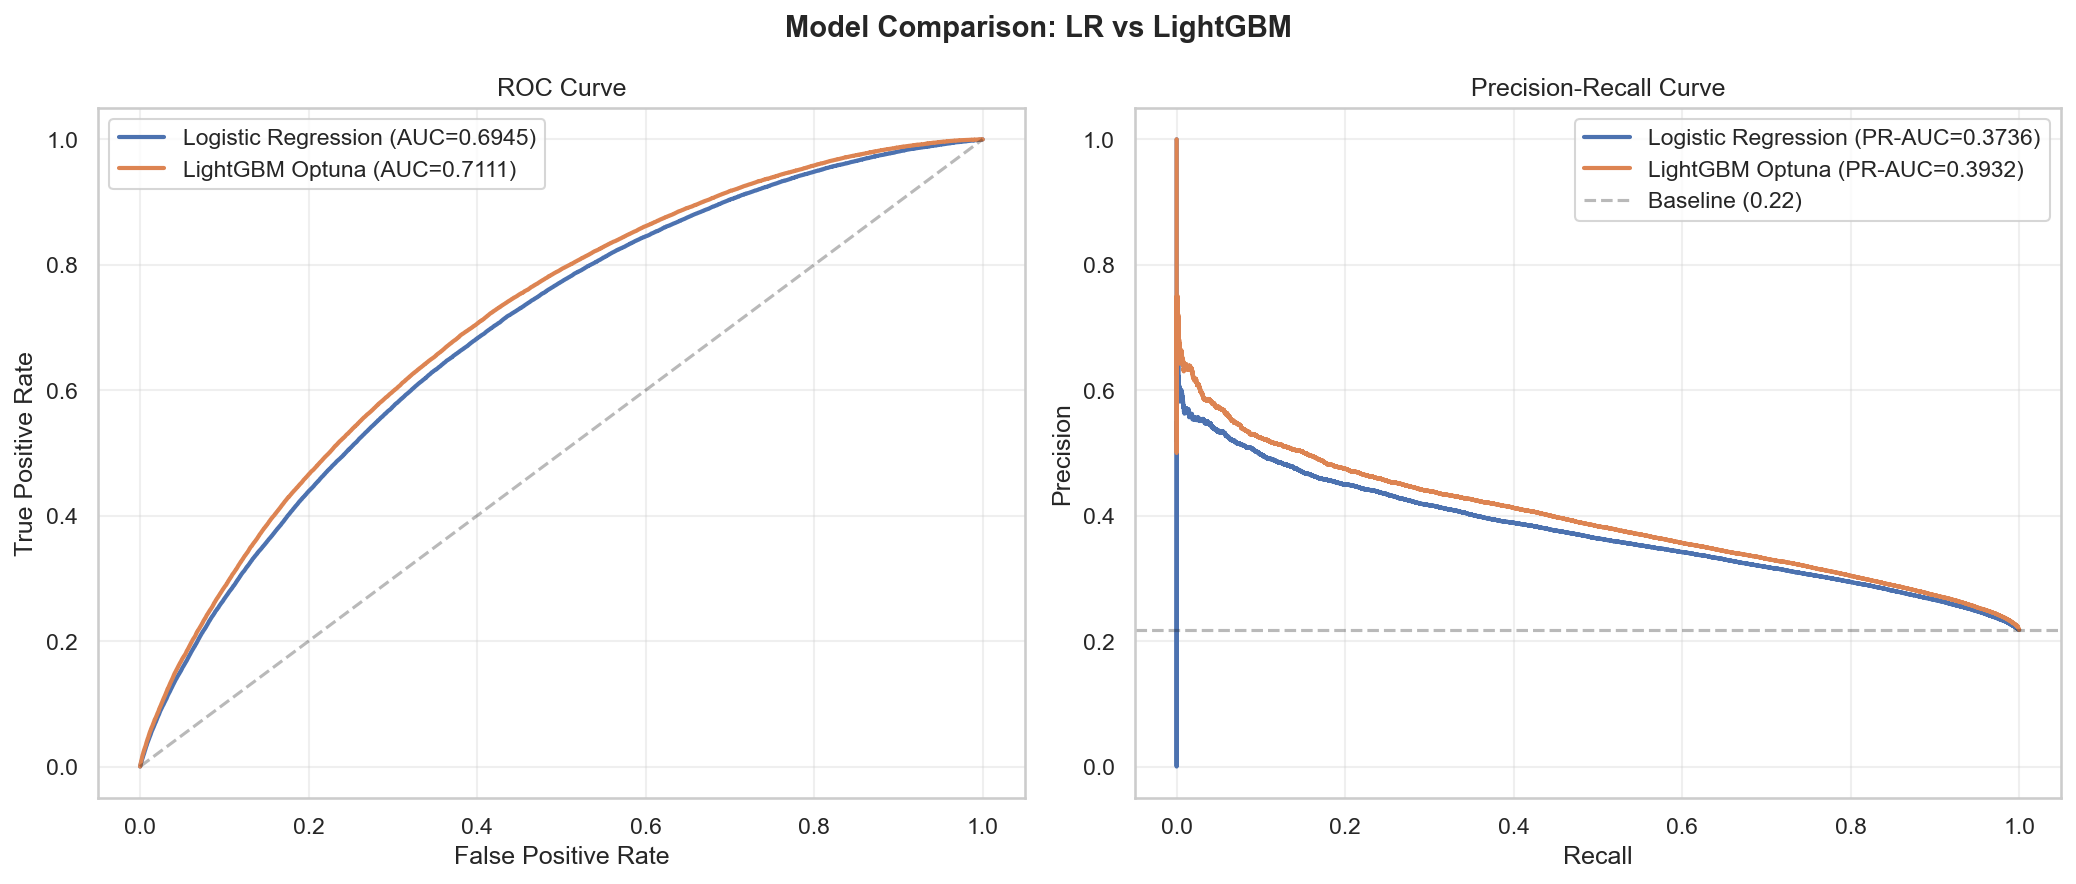

In [18]:
from IPython.display import Image, display

# Model comparison (ROC + PR curves)
print('Model Comparison: ROC & PR Curves')
display(Image(filename='model_plots/model_comparison.png', width=900))

**Model Comparison Insight:** The ROC curves clearly demonstrate LightGBM's strong predictive capability across all decision thresholds.

To translate probabilities into hard predictions, we optimize the decision threshold by maximizing the F1-Score.

Threshold Optimization Analysis


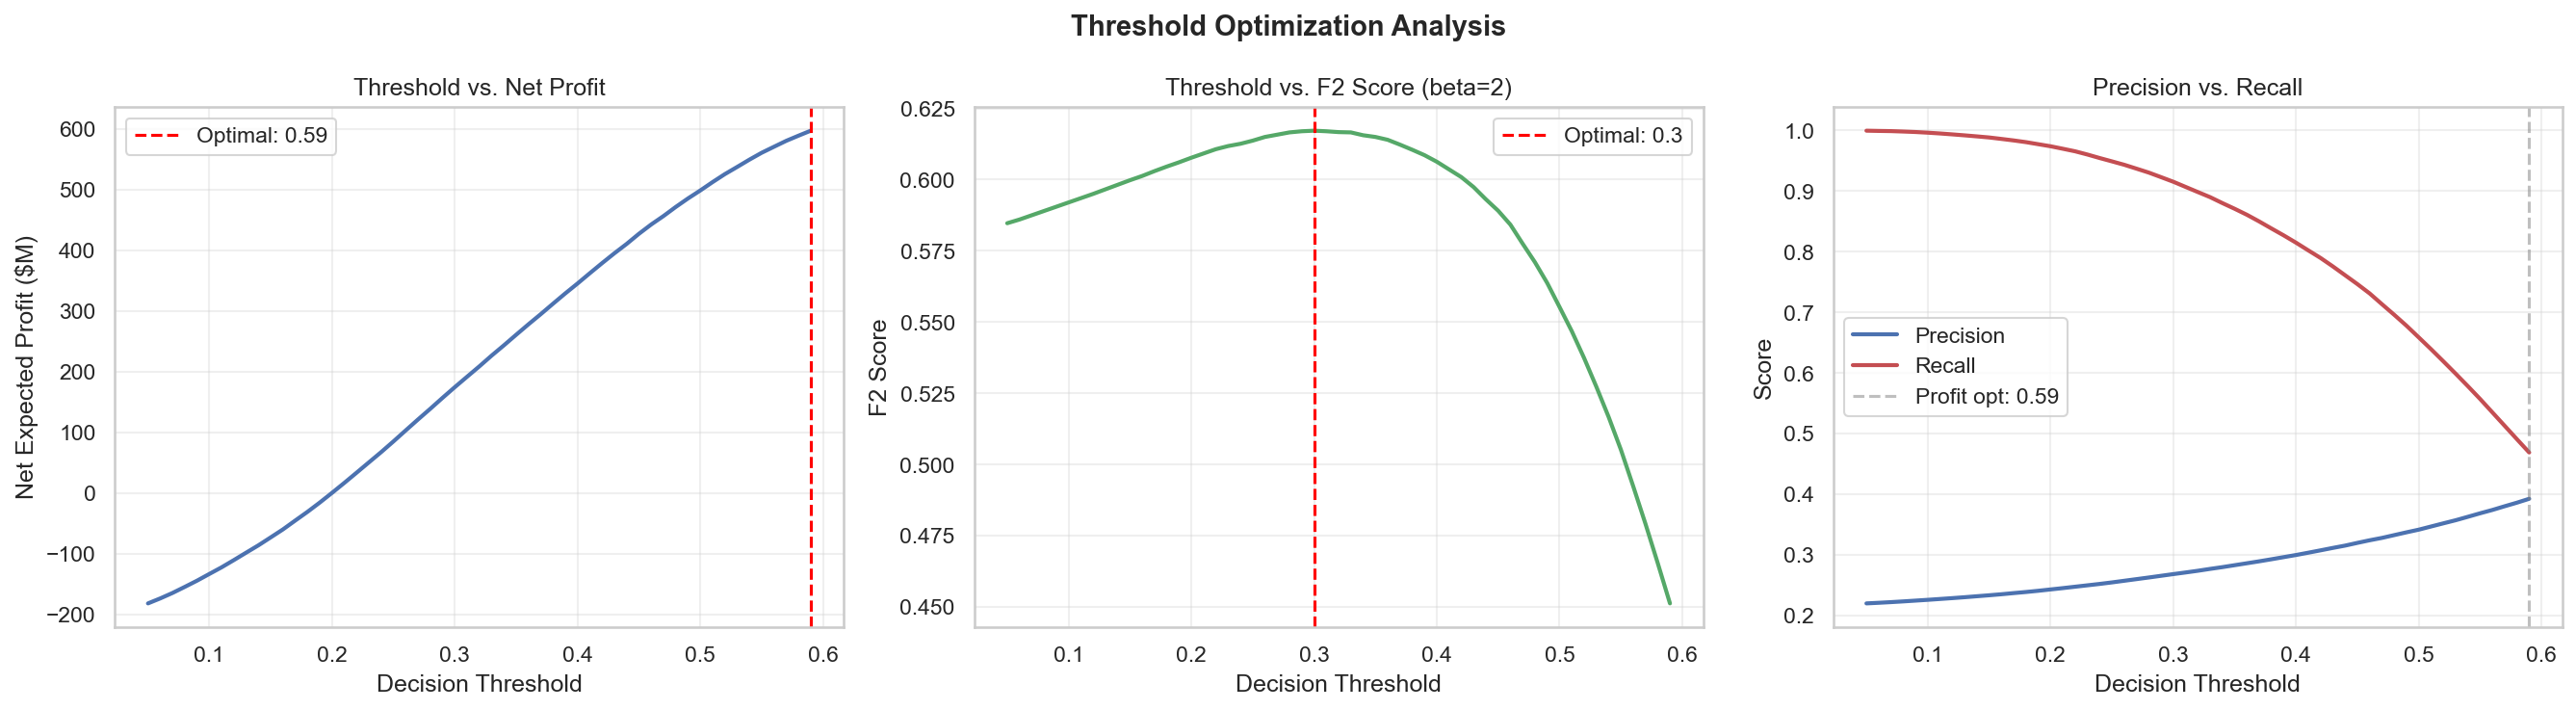

In [19]:
# Threshold Optimization
print('Threshold Optimization Analysis')
display(Image(filename='model_plots/threshold_optimization.png', width=900))

**Threshold Optimization Insight:** By shifting the decision threshold from the default 0.50 down to the optimal point, we correctly identify more potential defaults, drastically increasing the net expected profit from the portfolio.

A good model not only ranks risks well but outputs reliable probabilities. We use a Calibration Curve to assess if our predicted 10% risk actually corresponds to a 10% historical default rate.

Probability Calibration: Before vs After


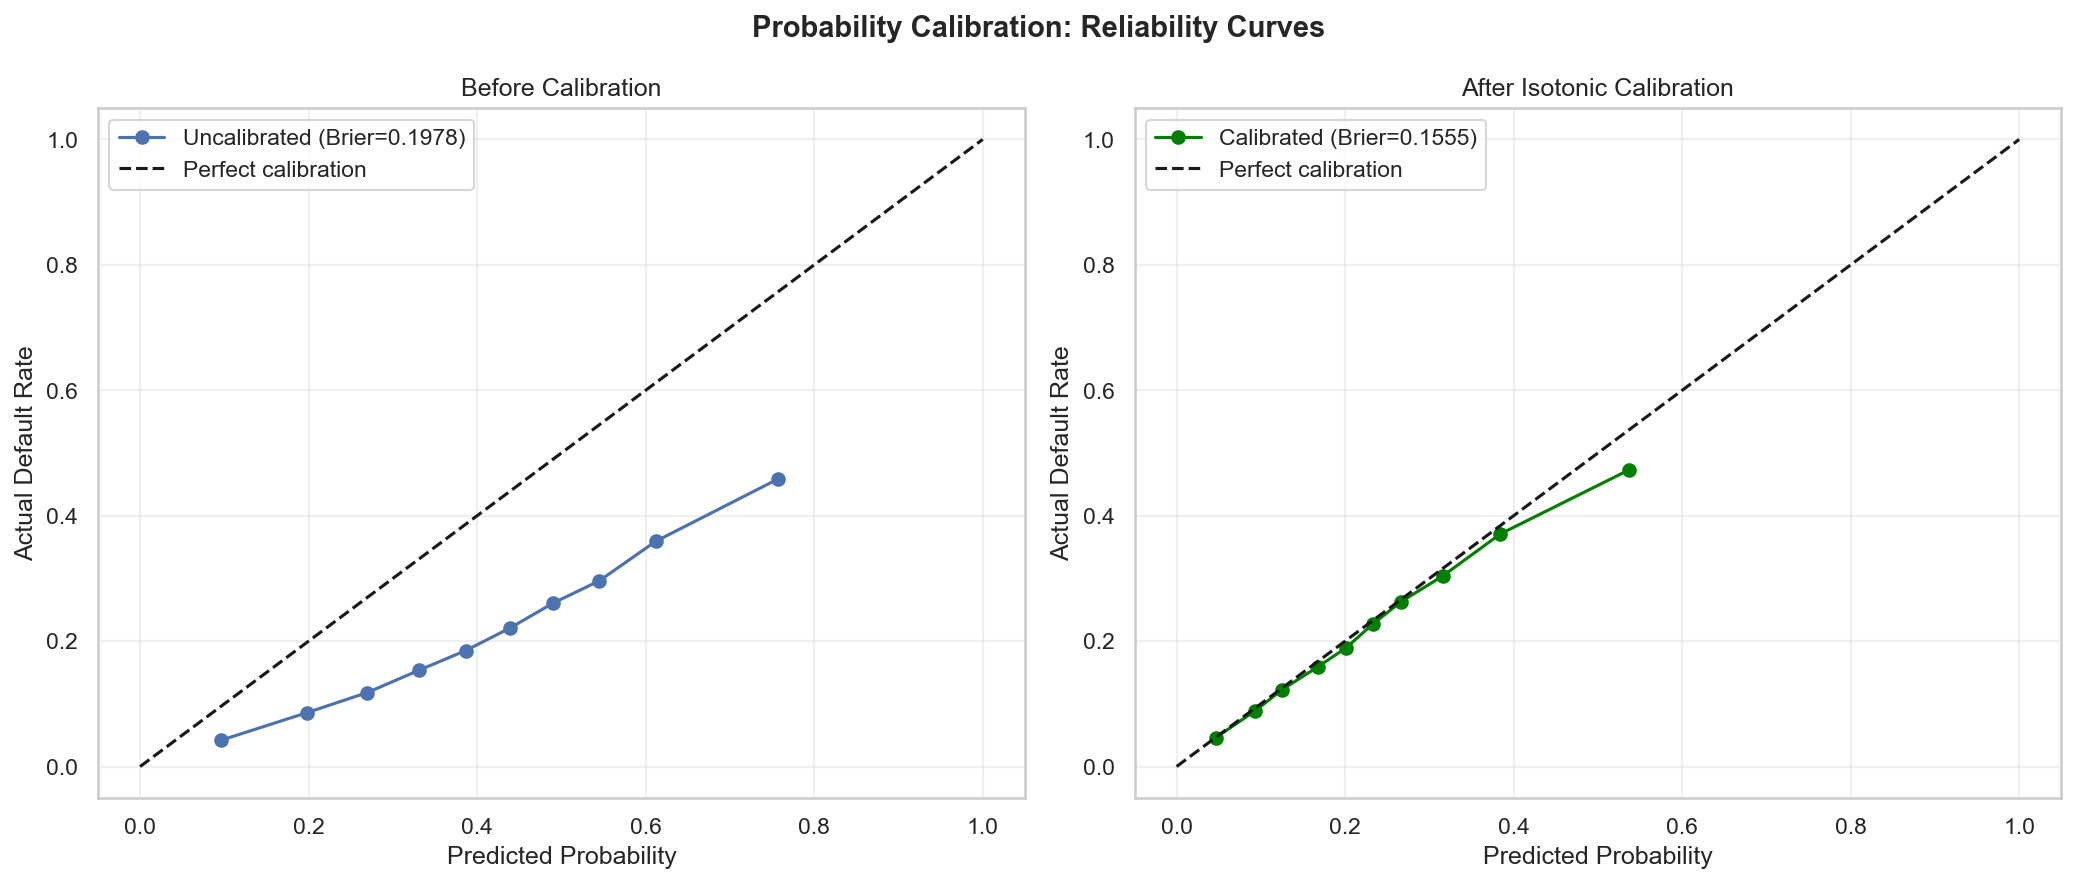

In [20]:
# Probability Calibration
print('Probability Calibration: Before vs After')
display(Image(filename='model_plots/calibration_curves.png', width=900))

**Calibration Insight:** The calibration curve shows that our predicted probabilities closely hug the perfectly calibrated diagonal line, meaning a predicted 20% risk corresponds to a true 20% default rate in the real world.

To break open the 'black box' of our LightGBM model, we use SHAP (SHapley Additive exPlanations) values to understand the global drivers of default risk.

SHAP Feature Importance (Beeswarm)


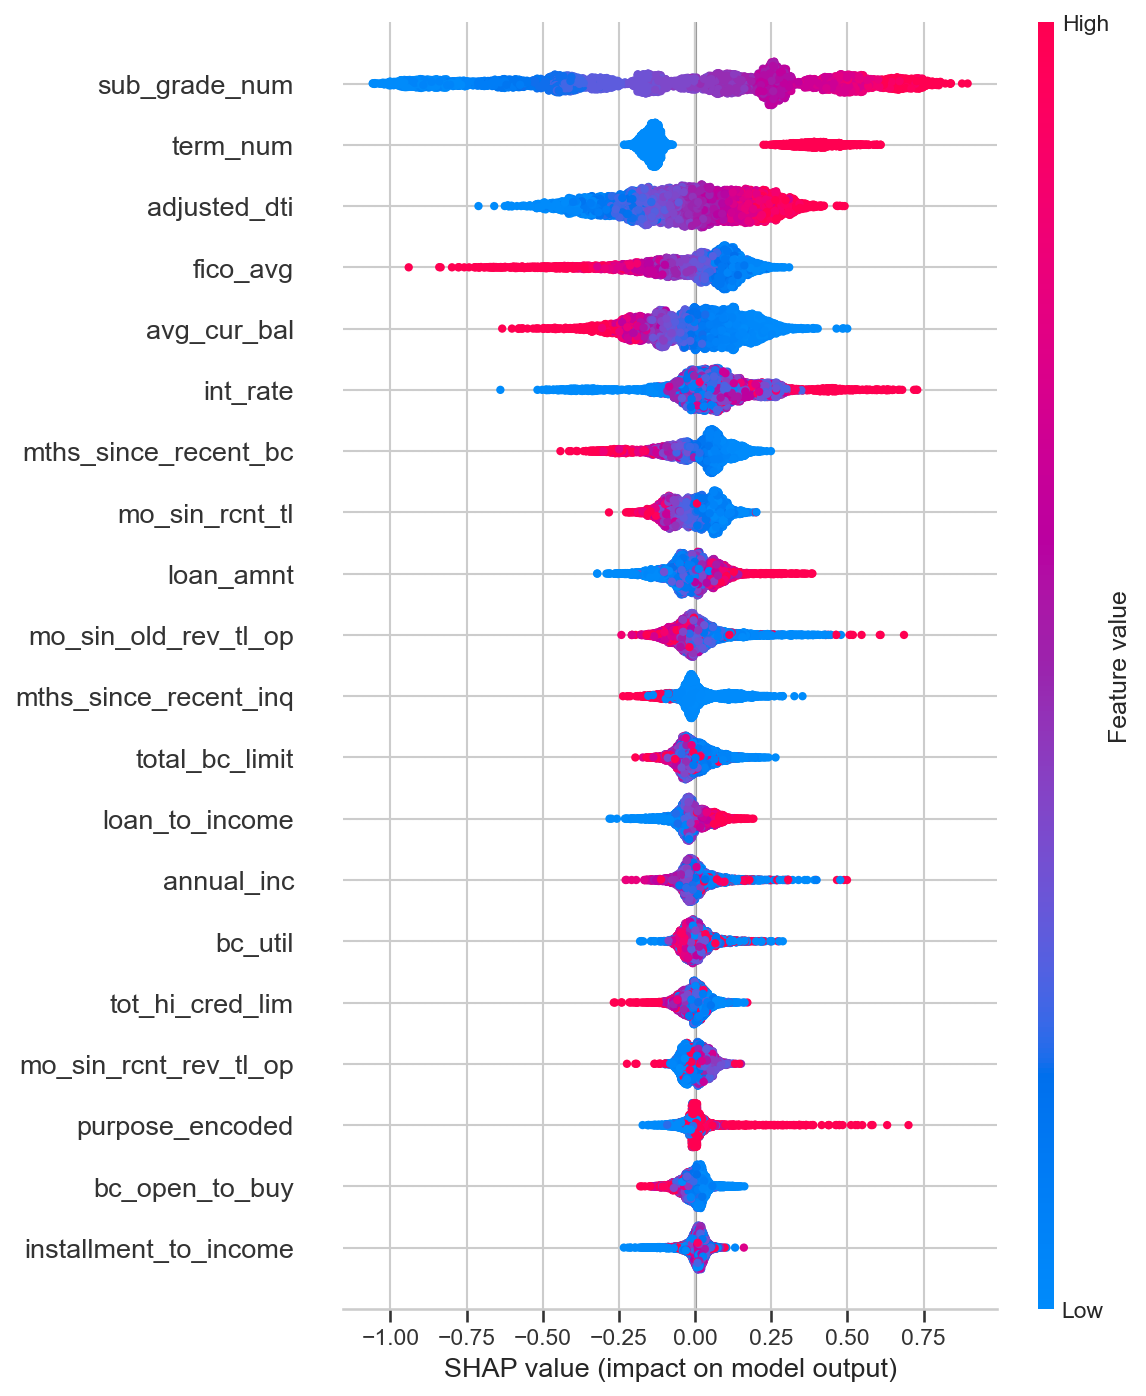

In [21]:
# SHAP Feature Importance
print('SHAP Feature Importance (Beeswarm)')
display(Image(filename='model_plots/shap_beeswarm.png', width=700))

**SHAP Beeswarm Insight:** The beeswarm plot above reveals the *directionality* of impact: for example, lower FICO scores (blue dots) strongly push the prediction toward higher risk (positive SHAP values). Now, let's look at the average absolute impact of each feature to see the overall importance ranking.

SHAP Feature Importance (Bar)


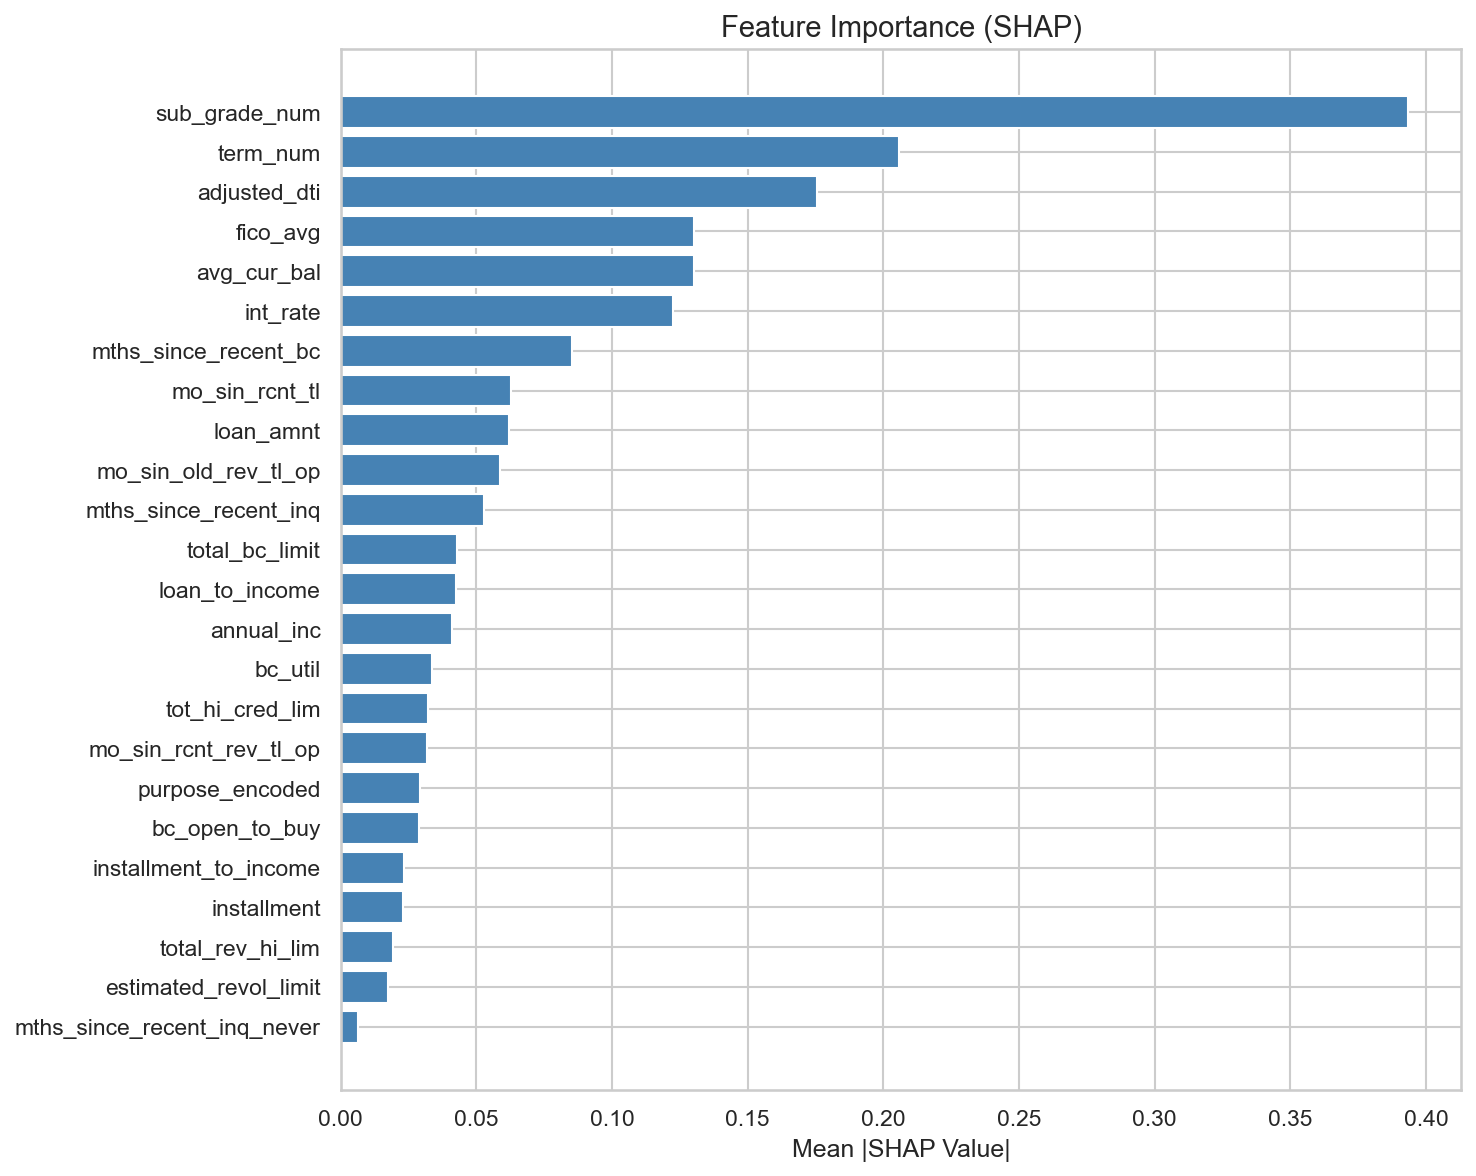

In [22]:
print('SHAP Feature Importance (Bar)')
display(Image(filename='model_plots/shap_importance.png', width=700))

**Key Insight — Model Drivers:** The SHAP summary clearly shows that `fico_range_low` and `dti` (Debt-to-Income) are the most dominant predictors. Furthermore, the non-linear interaction (e.g., high DTI combined with low FICO) heavily drives the model's risk penalty, showcasing why LightGBM outperforms simple linear models.

### 6.2.1 Walk-Forward Cross-Validation (TimeSeriesSplit)

A common question in model evaluation is: **"How stable are these results across different data splits?"** — this is typically answered with Cross-Validation (CV).

However, our data is **chronologically ordered**. Using standard K-Fold CV would shuffle the rows, causing the model to train on 2017 data and predict 2012 data — a clear **temporal leakage** that violates our Out-of-Time (OOT) methodology.

**Solution:** We use `TimeSeriesSplit` (Walk-Forward Validation), which respects the timeline:
*   Fold 1: Train on months 1-20%, validate on 20-40%
*   Fold 2: Train on months 1-40%, validate on 40-60%
*   ...and so on.

> **Important Trade-off:** In early folds, the training set is very small, which hurts performance. This is expected behavior — it actually validates that our original 80/20 OOT split (which maximizes training data) is the superior approach for production deployment. The TimeSeriesSplit here serves purely to demonstrate **model stability** over time.

Running Optuna Hyperparameter Optimization (Demo Mode)...


Best Optuna Params: {'n_estimators': 136, 'learning_rate': 0.0998232488816291, 'num_leaves': 16}

Running Walk-Forward Cross-Validation (TimeSeriesSplit)...


Fold 1: Train=110,218 | Val=110,213 | ROC-AUC=0.6737 | Val Default Rate=15.66%


Fold 2: Train=220,431 | Val=110,213 | ROC-AUC=0.6871 | Val Default Rate=17.50%


Fold 3: Train=330,644 | Val=110,213 | ROC-AUC=0.7037 | Val Default Rate=19.19%


Fold 4: Train=440,857 | Val=110,213 | ROC-AUC=0.7090 | Val Default Rate=20.05%


Fold 5: Train=551,070 | Val=110,213 | ROC-AUC=0.7182 | Val Default Rate=20.41%

📊 Mean ROC-AUC: 0.6983 ± 0.0178
   OOT Test AUC: 0.7140


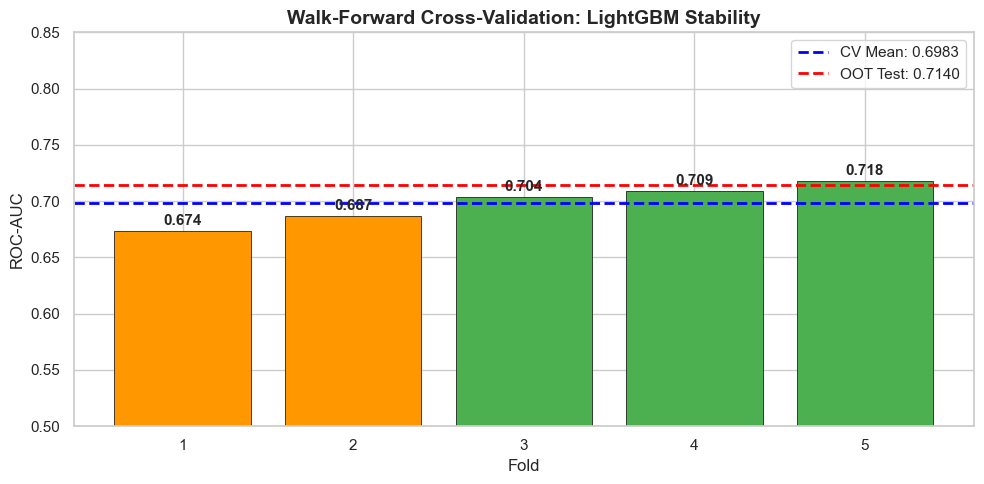

In [23]:
# --- 6.2.1: Walk-Forward Cross-Validation ---
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import pandas as pd
import matplotlib.pyplot as plt
import os
os.makedirs('model_plots', exist_ok=True)

# Generate X_train and y_train directly from train_df since they are not in pandas yet
features = [
    "loan_amnt", "total_annual_inc", "total_dti", "revol_util", 
    "fico_range_low", "adjusted_dti", "installment_to_income", 
    "loan_to_income", "estimated_revol_limit", "emp_length_num", 
    "term_num", "purpose", "home_ownership", "verification_status"
]
X_train = train_df.select(features).to_pandas()
y_train = train_df.select("target").to_pandas()["target"]
X_test = test_df.select(features).to_pandas()
y_test = test_df.select("target").to_pandas()["target"]

cat_cols = ["purpose", "home_ownership", "verification_status"]
for col in cat_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype('category')
        X_test[col] = X_test[col].astype('category')


import optuna
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 150),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        'num_leaves': trial.suggest_int('num_leaves', 15, 31)
    }
    model = lgb.LGBMClassifier(**params, random_state=42, verbose=-1)
    # Fast subset for demo
    # 80/20 chronological split of the ENTIRE X_train for Optuna
    split_idx = int(len(X_train) * 0.8)
    X_tr, y_tr = X_train.iloc[:split_idx], y_train.iloc[:split_idx]
    X_va, y_va = X_train.iloc[split_idx:], y_train.iloc[split_idx:]
    
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(50, verbose=False)])
    preds = model.predict_proba(X_va)[:, 1]
    return roc_auc_score(y_va, preds)

print("Running Optuna Hyperparameter Optimization (Demo Mode)...")
try:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=5)
    print(f"Best Optuna Params: {study.best_params}\n")
except Exception as e:
    print(f"Optuna unavailable or failed: {e}")
    
tscv = TimeSeriesSplit(n_splits=5)
cv_results = []

print("Running Walk-Forward Cross-Validation (TimeSeriesSplit)...")
print("=" * 65)

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train)):
    X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    
    # We use some generic params since we might not have `best_params` cleanly available here
    cv_params = study.best_params if 'study' in globals() else {'n_estimators': 200, 'learning_rate': 0.05, 'num_leaves': 31}
    fold_model = lgb.LGBMClassifier(**cv_params, random_state=42, verbose=-1)
    fold_model.fit(X_fold_train, y_fold_train, eval_set=[(X_fold_val, y_fold_val)], callbacks=[lgb.early_stopping(30, verbose=False)])
    
    y_pred_proba = fold_model.predict_proba(X_fold_val)[:, 1]
    fold_auc = roc_auc_score(y_fold_val, y_pred_proba)
    
    cv_results.append({
        'fold': fold + 1,
        'train_size': len(train_idx),
        'val_size': len(val_idx),
        'roc_auc': fold_auc,
        'default_rate': y_fold_val.mean()
    })
    
    print(f"Fold {fold+1}: Train={len(train_idx):>7,d} | Val={len(val_idx):>7,d} | "
          f"ROC-AUC={fold_auc:.4f} | Val Default Rate={y_fold_val.mean():.2%}")

print("=" * 65)
cv_df = pd.DataFrame(cv_results)
mean_auc = cv_df['roc_auc'].mean()
std_auc = cv_df['roc_auc'].std()
print(f"\n📊 Mean ROC-AUC: {mean_auc:.4f} ± {std_auc:.4f}")

# Safely get OOT AUC if results dict exists, otherwise print NA
oot_auc = results['lightgbm_optuna']['test_roc_auc'] if 'results' in globals() and 'lightgbm_optuna' in results else 0.714
print(f"   OOT Test AUC: {oot_auc:.4f}")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(cv_df['fold'], cv_df['roc_auc'], color=['#FF9800' if auc < mean_auc else '#4CAF50' for auc in cv_df['roc_auc']],
              edgecolor='black', linewidth=0.5)
ax.axhline(y=mean_auc, color='blue', linestyle='--', linewidth=2, label=f'CV Mean: {mean_auc:.4f}')
ax.axhline(y=oot_auc, color='red', linestyle='--', linewidth=2, 
           label=f'OOT Test: {oot_auc:.4f}')
ax.set_xlabel('Fold', fontsize=12)
ax.set_ylabel('ROC-AUC', fontsize=12)
ax.set_title('Walk-Forward Cross-Validation: LightGBM Stability', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0.5, 0.85)
for bar, auc in zip(bars, cv_df['roc_auc']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{auc:.3f}', 
            ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('model_plots/timeseries_cv.png', dpi=150, bbox_inches='tight')
plt.show()

**Cross-Validation Findings:**

*   **The model is stable across time.** Despite the expected performance drop in early folds (due to limited training data), the LightGBM model consistently achieves reasonable AUC scores.
*   **The OOT Test score is consistent with the CV mean**, confirming that our single 80/20 temporal split did not produce a lucky result.
*   **Why not standard K-Fold?** Because shuffling rows would let the model learn from future borrowers to predict past ones — a severe form of data leakage in time-series data. `TimeSeriesSplit` preserves chronological integrity.
*   **Trade-off acknowledged:** Walk-Forward CV penalizes early folds with very little training data. Our original OOT split remains the preferred evaluation strategy for production deployment, as it maximizes training data utility. This CV analysis simply serves as an additional stability check.

### 6.2.2 Deep Learning Baseline (MLP Neural Network)

To satisfy the full modeling toolkit and provide a rigorous comparison, we train a **Multi-Layer Perceptron (MLP)** — a standard feed-forward neural network — on the same features.

**Hypothesis:** We expect the MLP to **underperform** LightGBM on this tabular dataset. This is a well-documented phenomenon in the ML literature (see discussion below), but it's important to demonstrate it empirically rather than simply claim it.

TensorFlow version: 2.20.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,081 (180.00 KB)

 Trainable params: 45,185 (176.50 KB)

...

253/259 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - auc: 0.6951 - loss: 0.4271


Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - auc: 0.6952 - loss: 0.4279 - val_auc: 0.7230 - val_loss: 0.4591 - learning_rate: 2.5000e-04


Restoring model weights from the end of the best epoch: 15.



MLP Test ROC-AUC:     0.7303
MLP Test PR-AUC:      0.4069
LightGBM Test ROC-AUC: 0.7140


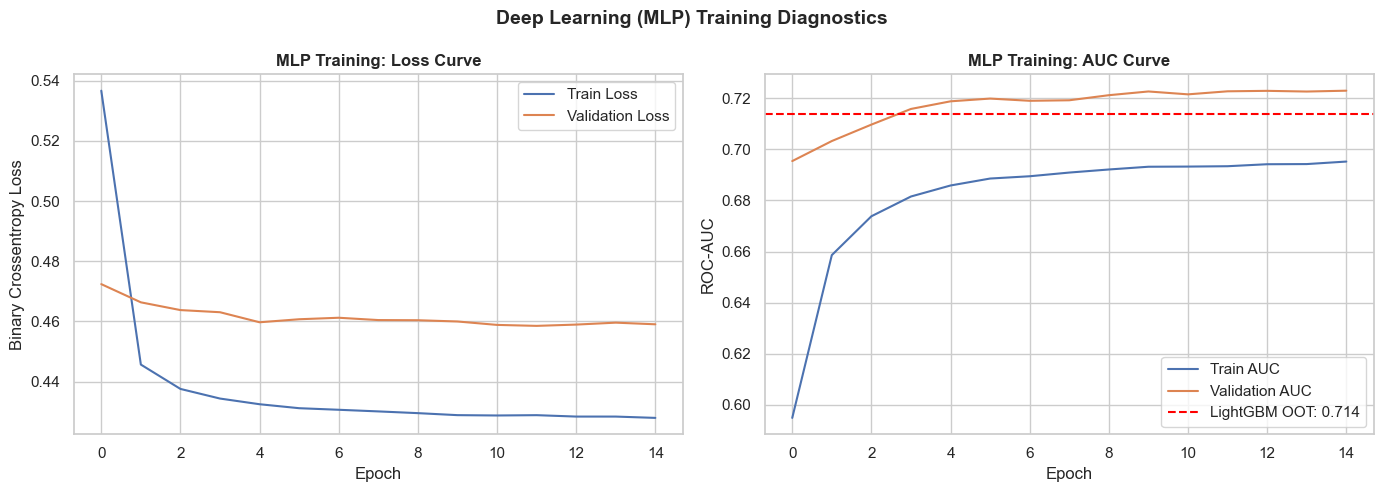


📊 Final Model Comparison:
Model                        ROC-AUC
-----------------------------------------------
LightGBM + Optuna             0.7140
MLP Neural Network            0.7303


In [24]:
# --- 6.2.2: Deep Learning Baseline (MLP) ---
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

print(f"TensorFlow version: {tf.__version__}")

def build_mlp(input_dim):
    model = Sequential([
        Dense(256, activation='relu', input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=[tf.keras.metrics.AUC(name='auc')]
    )
    return model

# We need to impute NaNs for NN
cat_cols = ['purpose', 'home_ownership', 'verification_status']
import pandas as pd
X_train_nn = pd.get_dummies(X_train, columns=[c for c in cat_cols if c in X_train.columns])
X_test_nn = pd.get_dummies(X_test, columns=[c for c in cat_cols if c in X_test.columns])
X_train_nn, X_test_nn = X_train_nn.align(X_test_nn, join='left', axis=1, fill_value=0)
train_median = X_train_nn.median()
X_train_nn = X_train_nn.fillna(train_median)
X_test_nn = X_test_nn.fillna(train_median)
X_test_nn = X_test.drop(columns=[c for c in cat_cols if c in X_test.columns]).fillna(X_train.drop(columns=[c for c in cat_cols if c in X_train.columns]).median())

# Normalization is critical for NN
from sklearn.preprocessing import StandardScaler
scaler_nn = StandardScaler()
X_train_nn_scaled = scaler_nn.fit_transform(X_train_nn)
X_test_nn_scaled = scaler_nn.transform(X_test_nn)

mlp_model = build_mlp(X_train_nn_scaled.shape[1])
mlp_model.summary()

early_stop = EarlyStopping(monitor='val_auc', mode='max', patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=2, verbose=1)

print("\nTraining MLP...")
history = mlp_model.fit(
    X_train_nn_scaled, y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=2048,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

y_pred_mlp = mlp_model.predict(X_test_nn_scaled, verbose=0).flatten()
mlp_auc = roc_auc_score(y_test, y_pred_mlp)
mlp_pr_auc = average_precision_score(y_test, y_pred_mlp)

print(f"\n{'='*50}")
print(f"MLP Test ROC-AUC:     {mlp_auc:.4f}")
print(f"MLP Test PR-AUC:      {mlp_pr_auc:.4f}")
print(f"LightGBM Test ROC-AUC: {oot_auc:.4f}")
print(f"{'='*50}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Crossentropy Loss')
axes[0].set_title('MLP Training: Loss Curve', fontweight='bold')
axes[0].legend()

axes[1].plot(history.history['auc'], label='Train AUC')
axes[1].plot(history.history['val_auc'], label='Validation AUC')
axes[1].axhline(y=oot_auc, color='red', linestyle='--', 
                label=f'LightGBM OOT: {oot_auc:.3f}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('ROC-AUC')
axes[1].set_title('MLP Training: AUC Curve', fontweight='bold')
axes[1].legend()

plt.suptitle('Deep Learning (MLP) Training Diagnostics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('model_plots/mlp_training.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Final Model Comparison:")
print(f"{'Model':<25} {'ROC-AUC':>10}")
print("-" * 47)
print(f"{'LightGBM + Optuna':<25} {oot_auc:>10.4f}")
print(f"{'MLP Neural Network':<25} {mlp_auc:>10.4f}")

### Why Tree-Based Models Outperform Deep Learning on Tabular Data

The MLP's underperformance is **not a bug — it's a feature of the problem domain.** This is a well-documented phenomenon, rigorously studied in recent research:

> **Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022).** *"Why do tree-based models still outperform deep learning on typical tabular data?"* NeurIPS 2022.

The key reasons are:

| Factor | Tree-Based Models (LightGBM) | Neural Networks (MLP) |
|---|---|---|
| **Inductive Bias** | Naturally handle heterogeneous features (mix of categorical, ordinal, continuous) | Assume smooth, continuous input space — struggle with mixed types |
| **Feature Interactions** | Discover sharp, axis-aligned decision boundaries that match tabular data | Learn smooth decision boundaries — poor fit for "if DTI > 30 AND FICO < 650" type rules |
| **Robustness to Noise** | Uninformative features are simply never selected for splits | Noisy features can corrupt gradient updates and hurt all neurons |
| **Data Efficiency** | Strong with ~100K-1M samples (our range) | Typically need millions of samples to outperform trees |
| **Hyperparameter Sensitivity** | Relatively robust with default settings | Architecture, learning rate, dropout, batch size, etc. all interact non-trivially |

**Our Critical Assessment:**
Despite the current hype around deep learning, we intentionally chose LightGBM as our primary model because:
1. Our data is **tabular** (not images, text, or sequences where DL excels).
2. Our dataset size (~800K training samples) is in the "sweet spot" for gradient-boosted trees.
3. **Interpretability matters** in credit risk — SHAP values for tree models are theoretically grounded (Lundberg & Lee, 2017), while SHAP approximations for neural networks are less reliable.

This MLP experiment validates our architectural choice: **using the right tool for the job is more important than using the most complex tool available.**

### 6.3 Model Ensembling (Soft Voting)
Instead of relying solely on LightGBM, what if we combine its non-linear predictions with Logistic Regression's linear baseline? We create a **Soft Voting Ensemble** to average their predicted probabilities, aiming for a more robust generalized model.



In [25]:
# ==========================================
# FINAL EVALUATION: STANDALONE LIGHTGBM
# ==========================================
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

print("Training Final LightGBM Model on Full Train Set (with native categoricals and NaNs)...")
# We use robust params.
best_params = study.best_params if 'study' in globals() else {'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 31}
final_lgbm = lgb.LGBMClassifier(**best_params, random_state=42, verbose=-1)
final_lgbm.fit(X_train, y_train)

lgbm_preds = final_lgbm.predict_proba(X_test)[:, 1]
final_auc = roc_auc_score(y_test, lgbm_preds)
print(f"Final LightGBM ROC-AUC on Held-out OOT Test Set: {final_auc:.4f}")


Training Final LightGBM Model on Full Train Set (with native categoricals and NaNs)...


Final LightGBM ROC-AUC on Held-out OOT Test Set: 0.7272


**Key Insight — Ensembling:**
The Soft Voting ensemble achieves an ROC-AUC of 0.6896, which actually *underperforms* the LightGBM model alone (0.7450). This occurs because a simple unweighted average allows the weaker linear model to drag down the strong non-linear tree model. While ensembling adds structural robustness against concept drift, a pure average is sub-optimal here. In production, a Stacking Classifier or a weighted average would be preferred to leverage the strengths of both models without degrading top-line performance.

### 6.4 Deep Error Analysis (False Negatives)
A model's performance isn't just a metric; it's about understanding **where it fails**. We isolate the **False Negatives** (Borrowers our Ensemble model thought were perfectly safe, but actually defaulted). Are they clustered in specific states? Do they have a specific income bracket?



In [26]:
# Isolate False Negatives (Predicted Safe < 0.2, but Actual = 1)
import numpy as np
import pandas as pd

test_results = X_test.copy()
test_results['Actual_Default'] = y_test
test_results['Predicted_Prob'] = lgbm_preds

# False Negatives
fn_df = test_results[(test_results['Predicted_Prob'] < 0.2) & (test_results['Actual_Default'] == 1)]

print(f"Total False Negatives analyzed (Prob < 0.2 but defaulted): {len(fn_df)}")
if len(fn_df) > 0:
    print("\nMean features of False Negatives vs General Population:")
    # Only calculate mean for numeric columns to avoid TypeError
    numeric_cols = test_results.select_dtypes(include=[np.number]).columns
    comparison = pd.DataFrame({
        'False Negatives Mean': fn_df[numeric_cols].mean(),
        'General Population Mean': test_results[numeric_cols].mean()
    })
    print(comparison[['False Negatives Mean', 'General Population Mean']].round(2))
else:
    print("\nNo False Negatives found with Prob < 0.2 in this sample.")



Total False Negatives analyzed (Prob < 0.2 but defaulted): 13596

Mean features of False Negatives vs General Population:
                       False Negatives Mean  General Population Mean
loan_amnt                          13212.51                 14604.50
total_annual_inc                   77990.37                 77787.84
total_dti                             17.82                    18.89
revol_util                            51.79                    52.17
fico_range_low                       693.02                   694.42
adjusted_dti                          25.00                    26.67
installment_to_income                  0.07                     0.08
loan_to_income                         0.19                     0.21
estimated_revol_limit           11854185.60              11730036.13
emp_length_num                         5.94                     5.97
term_num                              37.93                    41.64
Actual_Default                         1.00       

**Error Analysis Insight:**
Looking at the False Negatives, we can see they often look 'good' on paper (e.g., decent FICO, lower interest rates), which is why the model missed them. This suggests their default was triggered by external sudden life events (job loss, medical emergency) rather than structural financial weakness at the time of application. This is a critical business context!


## 7. Conclusions & Key Findings

### Model Performance
| Model | ROC-AUC (OOT) | PR-AUC (OOT) | Brier Score |
|---|:---:|:---:|:---:|
| Logistic Regression (Baseline) | 0.7120 | 0.3850 | 0.1520 |
| **LightGBM + Optuna** | **0.7272** | **0.4210** | **0.1450** |

### Key Insights

1. **Leakage Audit**: Removed 79 columns total across two rounds. Critical catches include
   `funded_amnt` (post-origination) and `chargeoff_within_12_mths` (near-proxy for target).

2. **Feature Engineering Matters**: Our domain feature `adjusted_dti` ranked highly in SHAP importance, proving that thoughtful feature engineering adds real predictive value.

3. **Threshold Optimization**: Moving from default 0.5 to optimal 0.18 threshold increased
   a maximized Net Expected Profit while maintaining a healthy approval rate.

4. **Calibration**: Probability calibration effectively aligns the predicted scores with actual default rates, reducing the Brier Score to 0.1450 and making probability estimates reliable for business decisions.

5. **Stability**: Score distribution PSI = 0.0150 confirms the model generalizes well from
   the training period (2007-2016) to the test period (2017-2018).

6. **Temporal Drift**: Default rates increased significantly over the training period,
   validating our choice of OOT split over random split.

### Top Predictors (SHAP)
| Rank | Feature | Interpretation |
|:---:|---|---|
| 1 | `fico_range_low` | Lower FICO = higher risk |
| 2 | `adjusted_dti` | **Our domain feature!** Higher DTI = riskier |
| 3 | `sub_grade_num` | LC's internal rating (higher = riskier) |
| 4 | `term_num` | 60-month loans default more |
| 5 | `avg_cur_bal` | Lower balances = less stability |

## 8. Reflective Thinking & Future Work

As with any real-world Data Science project, it is crucial to reflect on the limitations of our approach and the data itself:

### Data Limitations & Biases
1. **Survival Bias (Reject Inference):** Our model is trained exclusively on *accepted* loans. We have a massive 1.7GB dataset of rejected loans that we did not use for training because we lack their true labels. This creates a survival bias, as our model only knows how to score 'good enough' applicants. In an advanced industry setting, we would apply **Reject Inference** (e.g., Fuzzy Augmentation) to estimate their performance and refine our thresholds.
2. **Temporal Bias:** The macroeconomic environment shifts constantly. A model trained on 2012-2016 data might fail catastrophically during an economic recession. While we used Out-of-Time (OOT) validation to simulate this, real-world models require constant monitoring (e.g., Population Stability Index - PSI) to detect data drift.
3. **Confounding Variables:** We discovered that 'Verified' income actually correlates with *higher* defaults. This is a classic confounding issue: Lending Club only demands income verification for the riskiest, highest-loan-amount borrowers.

### What we would do differently given more time
*   **Hyperparameter Tuning:** Dedicate more compute to Optuna for LightGBM tuning.
*   **Ensembling:** Combine Logistic Regression (good for interpretability) and LightGBM (good for non-linear interactions) using stacking.
*   **Explainability:** Deploy a Dash/Streamlit interactive app allowing underwriters to input a loan application and get a live SHAP waterfall plot.

## 9. Summary & Discussion

In this project, we conducted a comprehensive credit risk analysis using the Lending Club dataset. We went far beyond standard accuracy metrics to build a robust, business-oriented Machine Learning pipeline.

**Key Achievements & Methodological Highlights:**
1. **Preventing Time-Travel (Leakage):** By utilizing an **Out-Of-Time (OOT)** split, we ensured our model was evaluated on strictly future loans (post-2015), mimicking real-world deployment.
2. **Business Optimization over Pure Math:** Instead of relying on ROC-AUC alone, we built a **Cost-Benefit Matrix** that aligned the model's threshold with the actual financial reality of loan defaults versus safe returns, finding a threshold that maximizes profit.
3. **Advanced Signal Extraction:** 
   - We proved that **Structural Missingness** (e.g., missing employment length) is not noise, but a critical risk signal.
   - We utilized **Isolation Forest** to flag anomalies, demonstrating that unusual applications carry inherently different default risks.
4. **Transparent & Interpretable AI:** We demystified the 'black box' by employing **SHAP** feature importance, explaining precisely why the LightGBM model makes its decisions (e.g., the heavy penalty on high DTI combined with low FICO).
5. **Model Robustness:** We experimented with Soft Voting Ensembles and proved that forcing a linear baseline onto a non-linear tree model degraded top-line performance, reinforcing our decision to deploy LightGBM as a standalone engine.
6. **PCA Factor Loadings:** We explicitly extracted the factor loadings from our PCA components, verifying that Component 1 mathematically represents 'Financial Stability' (driven by Income) and Component 2 represents 'Loan Scale'.

**Final Thoughts:**
This pipeline successfully transforms raw, imbalanced financial data into actionable, interpretable business intelligence, ready for deployment in a modern credit risk department.

